# Trabajo final · Data Scientist · Vidriera

**Tienda online** · Empresa ficticia. Los datos son sintéticos y **se generan por código en este notebook**: ningún resultado representa una situación real.

## La pregunta oficial

> **¿Qué pedidos hay que frenar o revisar antes de despachar?**

**Decisión que habilita:** Cuáles se bloquean, cuáles se revisan a mano (con capacidad para 40 por día) y cuáles se aprueban.

**Tipo de problema:** Clasificación extrema con etiquetas demoradas.

Las instrucciones completas (qué se entrega, criterios de calidad y defensa) están en el PDF **«Trabajo final · Data Scientist · Instrucciones»**. Este notebook es tu lugar de trabajo: vas de los datos sucios a la recomendación sin salir de acá.

| Sección | Módulo del programa |
| --- | --- |
| 1 | Introducción: definición del problema |
| 2 | Python: limpieza |
| 3 | Estadística |
| 4 | Machine Learning y regresión |
| 5 | Deep Learning |
| 6 | Apache Superset |
| 7 | De modelo a producción |
| 8 | Ciencia de datos aplicada al negocio |
| 9 | Fichas y recomendación |

## 0 · Preparación

Ejecutá esta celda una sola vez. Instala también `xgboost` (lo usamos en la sección 4), `pyyaml` y `joblib` (sección 7).

In [1]:
%pip install -q numpy pandas scipy scikit-learn matplotlib xgboost pyyaml joblib

Note: you may need to restart the kernel to use updated packages.


## 1 · Datos y definición del problema

La celda siguiente **genera las tablas**. Tarda unos segundos. Después mirá qué hay con `inventario()` y `diccionario()`.

Antes de modelar, definí el problema: **tipo de problema, población, período, granularidad y variable objetivo**, y qué información está realmente disponible en el momento de decidir.

In [2]:
import zlib, base64
TEXTO = (
    "eNqlWd1y2zYWvs9TYNh1SyYyI9mW7dj1zmad6e7ObGNNmp1pVqPhQCQksyEJlj9KnNT7Lr3sRa/6CH6x/Q4AkqBEud1Zjy0RwMEB"
    "cH6+84GO01wWFcvqNL9jvGRZPmI5zyI84jePnjyJxIqtRSYKXgQRr2TpliKNk4RfHY2PTs9GbCOKiEdX3/CkFN7FE4afgl1Bk19A"
    "kUx9aOB1UgVFtm7mepfs9TWETsb4uWTRGM955L+NU1FWPM1dB8qnh+MJfh0Iv8L40dnxJRMfq4KHYSyz4RmT8eFk6nhqFzypeBAO"
    "yZ00mtkzGqxkUGE8EpjgYt8lTOIWfpxVYi2K0h2P2OkJPl5fe96I1VlcXTmvzCJZsOSlwCKT43N1lpUIbznaONOu8r7SVyMz3db6"
    "u7POsZfxzszS7OdWFrS62oV/K+vC3/CkFuUlg+l51o1F/E6uPgjxvhXIarGRGC+M41yzBPuajf3xGdwUl3nQSMFOH25FIVzVMRqe"
    "NZ3uGZiM4dWcx2UApdXeRY+n6lBxmusVxccc1shkkfLEnUDNCFJn09YaUIpTxklQxKJcP3KYKY4rw1tynLLY1+z0ki3r4pG9TM7V"
    "XqIiXlWNFdmfh+P2TEXhJUtFJSM5VjrDWxmHwp07YSGiuJLOiDmRWJqnJdJCVMgyZ9GcBpl4NVcm9I/UxwIaw1pWvOxrhBWOEaIj"
    "NjnamnzSzsXfZLrQMfIJsw/P/FOE2sQ/Y0+N5591PlWHJNti7sQ/9iBjOZ+mHU3R1znwmfIDuih/Erl24TKPHTLykadGz2kdZXJq"
    "vSDZnqtI6Qk6tRN294Kd0obGtBfXbQ17ZZvOY18yt7UQctKjtduAGZOC4y5alDEosibsOXMnelEKscNPFEmrgteRGI6H/JIVgqBT"
    "JZQWxNqDkXM+hbJIpDozrWSeELActdvBikG4bENrFwe0jm0E4mmsIt39j96Ht3cjwKdTaxV8GRM3R/lJKxvRyq/5W63/CxYmscCe"
    "ywuWyBInQRCiTdUC4YAv4B9immcsBCyLhOWI70iqyQKlYRAsbEQ7s9CMcAHrmXRP8+rObQI6qu5ycYWJEHkf8KyK1zX2oyRLwYvw"
    "loBbRK4GfoNrI+Zqex42mWqMye/Kq+Ox5xk5fdg4+qgVrhIpC9da5uluGDx9SlHv+byknbl6Z+3mewc+RI6iD4O5izVwTionlCCe"
    "qSMkVwZxRAfCiIrFsE7LOtU69qq2ZkLdiKQgmwX4DipZNeqwOz3DJ5VeVyK1Srgu5JXI8OfOBw04V7MX2o69uCQnm1ErOBvDGtBR"
    "+JFLmej1OGy5xhmabVJaH+kSY5+xQx0gwDhABNOftk6rwoROu8IcOheQGc6Co6k5/I2mBq94xb8peCrcz446qHOhMxCoDEVo4RPP"
    "QDQ845NwG0uhQV9oUQVB61Ylp6OzkJSoB/SY9EKXeSIpZB/J4AstDWdoG1yjpRWM0eoaz9DVwi1622f02ziKIbuJUWU9dBsrOp1J"
    "zQka+zoKetGpvtFWYIC2+r5v0KB4+HnF1xxooPMcTDGKiZHxRBA6JCyNy1Q2qMFEho6sBnNUCgh6buY3vlpkoRhdgK4lqkY4XwIX"
    "IvHRh50E73EwBDaKWSIyd+l53gLxmt+5np4+N35bQA+1/X0AuqVvrBXSlI7YpU6rlTze6iQOQhgAqRXKiTv2qeD6J7aOZqI2JE19"
    "W9RCA6Hep46NhV1UuukIzwYj8m1TTHDmFBjrUqKMVQ2dnCsYmbTLNnHW2WG3MPVWM7XJ7I0ikqa6f9iGpn7tGlGlv85gpayNe7uw"
    "mPzTyOPOb0ZqI4CQeI2CLQJ1/iuyoKcoeaDxxDXe9qC1FJUWA0uQuZbF1eKGLiC0qxu0buDIKNCxqs7XQQeCgGRBPcyOIFqJtGzE"
    "lCsKP5dxWcrMnfjnagKOOSGypZWrTBTZJm6164Pf+FaOWvTvr2+I713/kz7/9Y4+Z++I9GnFzss3pq4XOKUdJzSuy/i5WpcYZySD"
    "nK+3FqaJCnVgpU8QoSV4XsglPdOeVappqS5oGkxq835BSufqWtf4bcRUc9HXYUf1cP+Xep6uAzLtW6kPV5ah1jSA8EgdhbGV3bzj"
    "t1I2DVlXqNbvVbM15P+rSOFqjhDj1ETEUE8cJrKOrIUsmk0M2/5bmDJTl4LCcb5yPn9Vf4VgK6uin0VU0kbsxYvgxYsXyMt4xYoi"
    "AJECr/rKoGgzL/TuHQb8YeFICcUZ+4QYvaFQbet136YNv1k0Ia4GlbdoT/X9Xz5HgdFao4q2SmnjI/KXmdrQwN2yifwyg1Rn7PTq"
    "aAglGcUERWVABIOKmMKWCJyD8EXxNpKpRCJWMpPBRoD7xyFXpdEq5i1noHQgBHIQ3ps4C2NVZK1cA1FFgXoZw48q6x5+KyIkAj1/"
    "B2rH2TeCnr8V0PxJdb+twboefs60SKIz47Wof6wffsn05cws3/l+QlesCUXA+Lz9ONNBcN/RH1nGVbyRwwa0BLQRgaQ/1pQgNNI4"
    "8Z6uzalKtHUh63x552oy4mnA9lFqqSzaywGiCpi34LDnp2ADPNKAkadAUIOelrjf34zXvh/o66ziXJpC1po7hRMSUGaAcRyR3XRH"
    "LJXxRRkWuO0WsUKkii9xayODElDbur2tu+sxWbO5u37BDvHDaDbdPGq4XPOK2aBVDexfwF5tq41Cw9tu/Ibu9eJY5RSFreZ+dLXQ"
    "etLch+mzyD2iYA3phgACHOjKcWEVEZvFQZt6bMmeBm4a0O2G3+lKQv1dU2+tHyE6Lhr2pzrUk4m3ugoHi8fJJZvN7fP3Sgdmge7P"
    "/G5cM4Du2kSvlHBvQnmPKh+ItFKZ6xy8OzxIDw+itwd/vzj49uLgu387MI6taFieNfJOg5bbu75kG3TNfOOCNhpn89Yr/SOoY6pb"
    "PgFRwe9cgrmPFyP/aHXvEBVJOKLVGVEUfq9ohOnxqWdk93xPPb7jKXD8SMC4WXij7cVOdxdTaz0+63xr1p9o2nhw2o7m3T33JnnG"
    "mLlQpusCyVivubHK5Q8ipEvrh12rz/YzG1J7pZiKdagP+r0egfHLYo0cijO+O66G3/xtYGBKxKOZyBzDhIhS5uZNzcwuXR3bGeBH"
    "+q59y8HW81wU9E6Kl9qIM50lzdsERKRnu2ZA27TTxqPod3Rh28wxThuWMjY3HpppvrS76vFuzptjZzzTFaXOE+Xekqd5IlywrfAK"
    "M8mSWl0AhlipNybte3evvTjR9P3M2NDilh/jT8E0JtE1Z9an7rORUrfwenuZPLIPRQf2EHh1uuv/Bc5tKqyAsGu3YI+90r8OEGJa"
    "prl5y67iNoxUvRnLZJVx146Nm+4a44CcgOSCo4QCmsETFU1AkQVZAWnhgRaIlygNFA+vZUavKLBcVj262nZ90Q5vWARZ5XruXvs7"
    "Z/LjkhR47Cc2NMy+vrL+d2Ldn6/nA/ahWBhaYxDCzXUlovd8FAWdZ1qsvu6Hy/XoMddG0Y5Hu+vLHneSeW1ntu3W2jDivTd4tzTc"
    "FltsCG5rnDCZ24R1GHcoL8LE3Ken9P7N7+ZsmSx6fpA+P3hHEfGYWGtZs4eO3f6BLYxPH4E/rNoq28XAx6Qa3NLOpprcI40trGz2"
    "0c1o4+8MPB5R9N9GTPzsmBdN8ORM0aS1LO0AoIFr/bZO+U+9sjNvupoNUmBt7s3FuqqLTKt/8uTVP66vtxbpxyMaVJT0PaRQL7jM"
    "2DaRRLylEJVbMj1W2WzS6bHK5nFr5g63bHvoLTxcFNVhpcl1SzTNE66PYg3J0tlhnGhGsVQaqGObeKL18Kt6zY+eh1+bI/TZp21b"
    "iJYknTDcV5hCw4ffHIuZOqEsCiGbfw/YUvcj5RL6Gfbrli8622whBEpJnVCPMmEol8VesHCih185vZakjUB4ybNQ0uuWhKcPv6l/"
    "YBi7tHhinkCv6N2fAaIGXfSDUUBj9qGsmPy8PxJ6t2K9P1hUvZ3Hd8LNf1ycvZdjp4yZ6dBHgNjDLyTnbN2OrYa9z61c+fy4y7XS"
    "7Sy/aDqZbeFSMAQW7WlLgbpBXuhvOqY9fH//5L9whVkS"
)
exec(zlib.decompress(base64.b64decode(TEXTO)).decode())

datos = generar_datos()          # genera las tablas, con una semilla fija: todos los equipos de esta empresa ven lo mismo
globals().update(datos)          # cada tabla queda disponible como variable


In [3]:
SLUG = "07_Vidriera"
import os, sqlite3
import pandas as pd

def inventario():
    """Tablas disponibles: filas, columnas y porcentaje de celdas faltantes."""
    return pd.DataFrame([(n, len(df), len(df.columns), round(float(df.isna().mean().mean() * 100), 1)) for n, df in datos.items()], columns=["tabla", "filas", "columnas", "% de faltantes"])

def diccionario(tabla=None):
    """Qué significa cada columna. Es una descripción neutra: no dice qué está limpio ni cuándo se conoce cada dato."""
    return pd.DataFrame([(t, c, d) for t, cols in DICC.items() if tabla in (None, t) for c, d in cols.items()], columns=["tabla", "columna", "qué es"])

bitacora_calidad = pd.DataFrame(columns=["problema", "dónde", "filas afectadas", "qué decidimos y por qué"])
def anotar(problema, donde, filas, decision):
    """Deja anotado un problema de calidad y la decisión tomada. Es parte de la trazabilidad."""
    bitacora_calidad.loc[len(bitacora_calidad)] = [problema, donde, filas, decision]; return bitacora_calidad

def exportar_superset(carpeta="superset", **tablas):
    """Guarda las tablas que pases como archivo SQLite y como CSV, para conectar Apache Superset."""
    os.makedirs(carpeta, exist_ok=True); con = sqlite3.connect(f"{carpeta}/{SLUG}.db")
    for nombre, df in tablas.items():
        df.to_csv(f"{carpeta}/{nombre}.csv", index=False); df.astype({c: "object" for c in df.columns if str(df[c].dtype).startswith("str")}).to_sql(nombre, con, index=False, if_exists="replace")
    con.close(); print(f"Listo: {carpeta}/{SLUG}.db y un CSV por tabla. Conectá Superset a ese archivo."); return carpeta


In [4]:
inventario()

,tabla,filas,columnas,% de faltantes
0,pedidos,146380,10,0.3
1,pagos_contracargos,146287,5,59.6
2,clientes,49539,4,0.0
3,dispositivos,72772,3,0.0


In [5]:
diccionario()

,tabla,columna,qué es
0,pedidos,id_pedido,identificador del pedido
1,pedidos,fecha_hora,momento del pedido
2,pedidos,id_cliente,cliente
3,pedidos,importe,importe del pedido
4,pedidos,cantidad_items,cantidad de productos
5,pedidos,cuotas,cuotas elegidas
6,pedidos,metodo_pago,medio de pago
7,pedidos,pais_envio,país de envío
8,pedidos,id_dispositivo,dispositivo desde el que compró
9,pedidos,email,correo con el que compró


Una mirada rápida a cada tabla tal como llega, antes de tocar nada:

In [6]:
for nombre, tabla in datos.items():
    print(f"── {nombre}: {len(tabla):,} filas"); display(tabla.head(3))

── pedidos: 146,380 filas


,id_pedido,fecha_hora,id_cliente,importe,cantidad_items,cuotas,metodo_pago,pais_envio,id_dispositivo,email
0,40554,2025-03-18 23:22:49,9850,17528.01,1,12,billetera,AR,19698.0,cliente9849@icloud.com
1,49908,2025-04-05T21:24:37Z,24059,"44.044,60",1,1,credito,AR,48116.0,cliente24058@gmail.com
2,40064,2025-03-18 01:30:15,13114,"15.002,56",2,6,debito,AR,26226.0,cliente13113@outlook.com


── pagos_contracargos: 146,287 filas


,id_pedido,estado_pago,fecha_contracargo,motivo,monto
0,1,aprobado,NaN,NaN,NaN
1,2,aprobado,NaN,NaN,NaN
2,3,aprobado,NaN,NaN,NaN


── clientes: 49,539 filas


,id_cliente,fecha_alta,telefono_verificado,provincia
0,1,01/01/2024,True,Santa Fe
1,2,01/01/2024,True,Tucumán
2,3,2024-01-01,True,Santa Fe


── dispositivos: 72,772 filas


,id_dispositivo,primera_vez_visto,tipo
0,6,2025-04-12,movil_android
1,8,2025-08-10,movil_ios
2,28,2025-04-28,movil_ios


### Tu definición del problema

La completamos **antes** de modelar y la revisamos al final. Dos decisiones de fondo que se explican en las secciones 2 y 3:

* **Los pagos rechazados quedan afuera**: un pedido cuyo cobro fue rechazado no se despacha, así que no hay nada que frenar.
* **La etiqueta necesita 62 días para madurar**: el contracargo llega entre 10 y 61 días después del pedido. Un pedido más reciente que eso puede ser fraude y todavía no saberse. Por eso se modela solo con pedidos hasta el 14/08/2025 (62 días antes de la extracción del 15/10/2025).

In [7]:
definicion = {
    "tipo de problema": "Clasificación binaria extremadamente desbalanceada (≈0,7 % de positivos observados) con etiquetas demoradas. "
                        "La salida es un puntaje que ordena los pedidos para tres decisiones: bloquear, revisar a mano (40 por día) o aprobar.",
    "población": "Pedidos únicos (sin reintentos duplicados) con el cobro aprobado, es decir, los que se van a despachar.",
    "período": "Pedidos del 01/01/2025 al 30/09/2025; extracción de contracargos al 15/10/2025. "
               "Con etiqueta madura (usable para entrenar y evaluar): pedidos hasta el 14/08/2025.",
    "granularidad (una fila es…)": "Un pedido.",
    "variable objetivo": "fraude = 1 si el pedido recibió un contracargo con motivo «no_reconoce_compra» (el titular de la tarjeta desconoce la compra). "
                         "Los contracargos por «mercadería no recibida» no son fraude: son un problema logístico y se cuentan aparte.",
    "qué se sabe en el momento de decidir": "Los datos del pedido (importe, ítems, cuotas, medio de pago, país, hora, correo), la cuenta (antigüedad, teléfono verificado, provincia), "
                                           "el dispositivo y la historia PREVIA del cliente y del dispositivo. No se sabe el contracargo ni los pedidos posteriores.",
}
pd.DataFrame(definicion.items(), columns=["campo", "respuesta"]).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,campo,respuesta
0,tipo de problema,"Clasificación binaria extremadamente desbalanceada (≈0,7 % de positivos observados) con etiquetas demoradas. La salida es un puntaje que ordena los pedidos para tres decisiones: bloquear, revisar a mano (40 por día) o aprobar."
1,población,"Pedidos únicos (sin reintentos duplicados) con el cobro aprobado, es decir, los que se van a despachar."
2,período,Pedidos del 01/01/2025 al 30/09/2025; extracción de contracargos al 15/10/2025. Con etiqueta madura (usable para entrenar y evaluar): pedidos hasta el 14/08/2025.
3,granularidad (una fila es…),Un pedido.
4,variable objetivo,fraude = 1 si el pedido recibió un contracargo con motivo «no_reconoce_compra» (el titular de la tarjeta desconoce la compra). Los contracargos por «mercadería no recibida» no son fraude: son un problema logístico y se cuentan aparte.
5,qué se sabe en el momento de decidir,"Los datos del pedido (importe, ítems, cuotas, medio de pago, país, hora, correo), la cuenta (antigüedad, teléfono verificado, provincia), el dispositivo y la historia PREVIA del cliente y del dispositivo. No se sabe el contracargo ni los pedidos posteriores."


## 2 · Python

**Qué tenés que resolver en tu caso:** Resolver pedidos duplicados por reintentos, direcciones y correos con variantes, importes con coma y con punto, y fechas en distintas zonas horarias.

Limpiá **sin borrar en silencio**: cada decisión se anota con `anotar(...)` y queda en la bitácora de calidad.

Trabajamos sobre **copias** (`P`, `C`, `CL`, `DV`): las tablas originales quedan intactas para poder comparar antes y después.

In [8]:
import re, math, time, warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
AZUL, ROJO, GRIS, VERDE, NARANJA = "#2F6DB5", "#C8423B", "#9AA0A6", "#2E8B57", "#E08A1E"

EXTRACCION = pd.Timestamp("2025-10-15")      # día en que se bajaron los contracargos
P, C, CL, DV = pedidos.copy(), pagos_contracargos.copy(), clientes.copy(), dispositivos.copy()

### 2.1 Pedidos duplicados por reintento

Cuando el pago tarda, el cliente aprieta «comprar» otra vez y el sistema graba el mismo pedido con otro `id_pedido`. Lo detectamos como **filas idénticas en todo salvo el id**.

In [9]:
cols_sin_id = [c for c in P.columns if c != "id_pedido"]
P = P.sort_values("id_pedido")
es_reintento = P.duplicated(cols_sin_id, keep="first")
reintentos = P[es_reintento].copy()
pagos_de_copias = C[C.id_pedido.isin(reintentos.id_pedido)]
print(f"Reintentos: {es_reintento.sum():,} ({es_reintento.mean():.1%} de los pedidos)")
print(f"De esas copias, ¿cuántas tienen contracargo? {pagos_de_copias.fecha_contracargo.notna().sum()}  →  el contracargo siempre queda en el pedido original")
P = P[~es_reintento].copy()
_ = anotar("Pedidos duplicados por reintento (idénticos salvo el id_pedido)", "pedidos", int(es_reintento.sum()),
       "Se conserva el id más bajo (el original). Las copias nunca tienen contracargo: dejarlas inflaría los casos buenos. Quedan guardadas en `reintentos` para auditoría.")
_ = anotar("Filas de pago de los pedidos duplicados", "pagos_contracargos", len(pagos_de_copias),
       "Se descartan junto con su pedido: todas dicen 'aprobado' sin contracargo.")

Reintentos: 3,570 (2.4% de los pedidos)
De esas copias, ¿cuántas tienen contracargo? 0  →  el contracargo siempre queda en el pedido original


### 2.2 Fechas en dos zonas horarias

Una parte de las fechas viene en **UTC** (terminan en `Z`, como `2025-04-05T21:24:37Z`) y otra en **hora de Argentina** sin zona. Mezclarlas corre 3 horas a esos pedidos, y la hora importa: la compra de madrugada es una señal de riesgo. Llevamos todo a hora argentina.

In [10]:
es_utc = P.fecha_hora.str.endswith("Z")
hora_local = pd.to_datetime(P.fecha_hora.where(~es_utc), format="%Y-%m-%d %H:%M:%S", errors="coerce")
hora_utc = (pd.to_datetime(P.fecha_hora.where(es_utc), format="%Y-%m-%dT%H:%M:%SZ", utc=True, errors="coerce")
              .dt.tz_convert("America/Argentina/Buenos_Aires").dt.tz_localize(None))
P["fecha_hora"] = hora_local.fillna(hora_utc)
assert P.fecha_hora.notna().all(), "quedó alguna fecha sin interpretar"
print(f"Fechas en UTC convertidas: {es_utc.sum():,} ({es_utc.mean():.0%}).  Rango: {P.fecha_hora.min()} → {P.fecha_hora.max()}")
_ = anotar("Fechas mezcladas: UTC con 'Z' y hora local sin zona", "pedidos.fecha_hora", int(es_utc.sum()),
       "Se convierten las UTC a America/Argentina/Buenos_Aires (UTC−3). Sin esto, la hora del pedido queda corrida 3 horas en el 40 % de los casos.")

Fechas en UTC convertidas: 57,050 (40%).  Rango: 2025-01-01 00:00:58 → 2025-09-30 23:58:41


### 2.3 Importes con coma, con punto y con signo pesos

Conviven cuatro formatos: `44.044,60` (miles con punto), `24213,56` (coma decimal), `17528.01` (punto decimal) y `$17528` (redondeado). Primero verificamos que ningún texto sea ambiguo, después convertimos.

In [11]:
def formato_importe(s):
    s = str(s).strip()
    if s.startswith("$"): return "con $ y sin centavos"
    if "," in s and "." in s: return "miles con punto y coma decimal"
    if "," in s: return "coma decimal"
    return "punto decimal"

def a_numero(texto):
    s = str(texto).strip().replace("$", "").replace(" ", "")
    if "," in s and "." in s: s = s.replace(".", "").replace(",", ".")   # 44.044,60 → 44044.60
    elif "," in s: s = s.replace(",", ".")                              # 24213,56 → 24213.56
    return float(s)

texto_importe = P.importe.astype(str).str.strip()
ambiguos = texto_importe.str.fullmatch(r"\d{1,3}(\.\d{3})+")           # ¿"1.234" son mil o uno coma dos?
assert ambiguos.sum() == 0, "hay importes ambiguos: revisar a mano"
display(texto_importe.map(formato_importe).value_counts().rename("pedidos").to_frame())
P["importe"] = texto_importe.map(a_numero)
assert (P.importe > 0).all()
print(P.importe.describe(percentiles=[.01, .5, .99]).round(0))
redondeados = texto_importe.str.startswith("$")
_ = anotar("Importes en cuatro formatos (coma o punto decimal, miles con punto, $ redondeado)", "pedidos.importe", len(P),
       "Se convierten a número con una regla explícita; se verificó antes que no haya textos ambiguos como '1.234'.")
_ = anotar("Importes con $ vienen redondeados al peso", "pedidos.importe", int(redondeados.sum()),
       "Se conservan: la pérdida es de centavos y no cambia el riesgo. Queda la marca por si se necesita conciliar.")

,pedidos
importe,
miles con punto y coma decimal,49906
punto decimal,43132
con $ y sin centavos,28293
coma decimal,21479


count    142810.0
mean      32147.0
std       27639.0
min         694.0
1%         4240.0
50%       24318.0
99%      138807.0
max      522870.0
Name: importe, dtype: float64


### 2.4 Países, correos y provincias con variantes

In [12]:
print("Antes:", P.pais_envio.value_counts().to_dict())
P["pais_envio"] = P.pais_envio.str.strip().str.upper().replace({"ARGENTINA": "AR", "ARG": "AR"})
print("Después:", P.pais_envio.value_counts().to_dict())
cambia_pais = (pedidos.set_index("id_pedido").pais_envio.reindex(P.id_pedido).values != P.pais_envio.values).sum()
_ = anotar("País de envío escrito de cuatro formas (AR, Argentina, ARG, 'argentina ')", "pedidos.pais_envio", int(cambia_pais),
       "Se unifican al código ISO de dos letras. Sin esto, 'Argentina' parecería un país extranjero.")

email_crudo = P.email.astype(str)
P["email"] = email_crudo.str.strip().str.lower()
_ = anotar("Correos en mayúsculas o con espacios al final", "pedidos.email", int((email_crudo != P.email).sum()),
       "Se pasan a minúsculas y sin espacios. Si no, el mismo correo cuenta como dos y la variable 'correo ya usado por el cliente' se rompe.")

prov_cruda = CL.provincia.copy()
CL["provincia"] = CL.provincia.str.strip().str.title()
_ = anotar("Provincias en mayúsculas", "clientes.provincia", int((prov_cruda != CL.provincia).sum()), "Se normalizan a 'Título' (BUENOS AIRES → Buenos Aires).")

Antes: {'AR': 103355, 'Argentina': 16493, 'ARG': 11041, 'argentina ': 6840, 'PY': 1303, 'CL': 1288, 'UY': 1286, 'BR': 1204}
Después: {'AR': 137729, 'PY': 1303, 'CL': 1288, 'UY': 1286, 'BR': 1204}


### 2.5 Fechas de alta en dos formatos, dispositivos faltantes y pagos

In [13]:
alta_dmy = CL.fecha_alta.str.contains("/")
CL["fecha_alta"] = pd.to_datetime(CL.fecha_alta.where(alta_dmy), format="%d/%m/%Y", errors="coerce").fillna(
                   pd.to_datetime(CL.fecha_alta.where(~alta_dmy), format="%Y-%m-%d", errors="coerce"))
assert CL.fecha_alta.notna().all()
_ = anotar("Fecha de alta en dos formatos (dd/mm/aaaa y aaaa-mm-dd)", "clientes.fecha_alta", int(alta_dmy.sum()),
       "Se interpreta cada formato por separado, sin dejar que pandas adivine (01/02 podría leerse como 2 de enero).")

DV["primera_vez_visto"] = pd.to_datetime(DV.primera_vez_visto, format="%Y-%m-%d")
sin_disp = P.id_dispositivo.isna()
_ = anotar("Pedidos sin dispositivo", "pedidos.id_dispositivo", int(sin_disp.sum()),
       "No se borran ni se imputan: se agrega la marca 'disp_faltante'. La falta de dato puede ser informativa (en la sección 3 se ve que no lo es).")

C["fecha_contracargo"] = pd.to_datetime(C.fecha_contracargo, format="%Y-%m-%d")
sin_pago = ~P.id_pedido.isin(C.id_pedido)
print(f"Pedidos sin fila en pagos: {sin_pago.sum()}  ·  fechas entre {P.loc[sin_pago, 'fecha_hora'].min():%d/%m/%Y} y {P.loc[sin_pago, 'fecha_hora'].max():%d/%m/%Y}")
_ = anotar("Pedidos sin registro de pago", "pagos_contracargos", int(sin_pago.sum()),
       "Todos son de agosto y septiembre, fuera de la ventana madura: no se usan para entrenar ni evaluar. Se puntúan igual (el modelo no necesita el pago).")
rechazados = (C.estado_pago == "rechazado").sum()
_ = anotar("Cobros rechazados", "pagos_contracargos.estado_pago", int(rechazados),
       "Quedan fuera de la población (no se despachan), pero sí cuentan como intentos en las variables de velocidad del cliente.")

Pedidos sin fila en pagos: 93  ·  fechas entre 17/08/2025 y 30/09/2025


### 2.6 Integridad entre tablas

Revisamos que cada pedido encuentre su cliente y su dispositivo, y que la cuenta no se haya dado de alta después del pedido.

In [14]:
base = (P.merge(C, on="id_pedido", how="left", validate="1:1")
          .merge(CL, on="id_cliente", how="left", validate="m:1")
          .merge(DV, on="id_dispositivo", how="left", validate="m:1")
          .sort_values(["fecha_hora", "id_pedido"]).reset_index(drop=True))
chequeos = {
    "pedidos sin cliente en la tabla clientes": base.fecha_alta.isna().sum(),
    "pedidos con dispositivo que no está en la tabla dispositivos": (base.id_dispositivo.notna() & base.tipo.isna()).sum(),
    "cuenta dada de alta después del pedido": (base.fecha_alta.dt.normalize() > base.fecha_hora.dt.normalize()).sum(),
    "dispositivo 'visto por primera vez' después del pedido": (base.primera_vez_visto > base.fecha_hora.dt.normalize()).sum(),
    "contracargo anterior al pedido": (base.fecha_contracargo < base.fecha_hora.dt.normalize()).sum(),
    "monto reclamado distinto del importe (más de $1)": ((base.monto - base.importe).abs() > 1).sum(),
}
pd.Series(chequeos, name="filas").to_frame()

,filas
pedidos sin cliente en la tabla clientes,0
pedidos con dispositivo que no está en la tabla dispositivos,0
cuenta dada de alta después del pedido,0
dispositivo 'visto por primera vez' después del pedido,0
contracargo anterior al pedido,0
monto reclamado distinto del importe (más de $1),0


Los importes con `$` vienen redondeados, por eso puede haber diferencias de centavos con el monto reclamado: con tolerancia de $1 no queda ninguna.

### 2.7 Variables disponibles en el momento de decidir

Esta es la parte más delicada: **cada variable usa solo lo que se sabía cuando entró el pedido**. Por ejemplo, «pedidos del cliente en la última hora» cuenta los anteriores, nunca los posteriores (en la sección 4 mostramos qué pasa si se cuelan los posteriores). Las variables de velocidad se calculan sobre **todos los intentos**, incluidos los cobros rechazados, porque un rechazo seguido de otro intento es justamente una señal.

In [15]:
def construir_variables(b):
    """Variables por pedido usando solo información anterior o simultánea al pedido."""
    b = b.sort_values(["fecha_hora", "id_pedido"]).copy()
    b["hora"] = b.fecha_hora.dt.hour
    b["madrugada"] = (b.hora < 6).astype(int)
    b["fin_de_semana"] = (b.fecha_hora.dt.dayofweek >= 5).astype(int)
    b["log_importe"] = np.log(b.importe)
    b["envio_exterior"] = (b.pais_envio != "AR").astype(int)
    b["antig_cuenta_dias"] = ((b.fecha_hora - b.fecha_alta).dt.total_seconds() / 86400).clip(lower=0)
    b["cuenta_nueva_7d"] = (b.antig_cuenta_dias < 7).astype(int)
    b["telefono_verificado"] = b.telefono_verificado.astype(int)
    b["disp_faltante"] = b.id_dispositivo.isna().astype(int)
    b["disp_antig_dias"] = (b.fecha_hora.dt.normalize() - b.primera_vez_visto).dt.days        # NaN si no hay dispositivo
    b["disp_pedidos_previos"] = b.groupby("id_dispositivo").cumcount().where(b.id_dispositivo.notna())
    b["disp_nuevo"] = (b.disp_pedidos_previos == 0).astype(int)
    b["email_generico"] = b.email.str.match(r"^u\d{5}@").astype(int)                         # usuario tipo u12345@…
    b["email_corporativo"] = b.email.str.endswith(".com.ar").astype(int)
    b["email_ya_usado"] = (b.groupby(["id_cliente", "email"]).cumcount() > 0).astype(int)
    b["cli_pedidos_previos"] = b.groupby("id_cliente").cumcount()
    b["min_desde_anterior"] = (b.groupby("id_cliente").fecha_hora.diff().dt.total_seconds() / 60).fillna(1e5).clip(upper=1e5)
    # velocidad: pedidos ANTERIORES del mismo cliente en la última hora y en las últimas 24 h (closed="left" excluye el pedido actual)
    o = b.sort_values(["id_cliente", "fecha_hora", "id_pedido"])
    g = o.set_index("fecha_hora").groupby("id_cliente").id_pedido
    o["cli_pedidos_1h"] = g.rolling("1h", closed="left").count().fillna(0).values
    o["cli_pedidos_24h"] = g.rolling("24h", closed="left").count().fillna(0).values
    b = o.sort_values(["fecha_hora", "id_pedido"]).reset_index(drop=True)
    b["rafaga"] = (b.cli_pedidos_1h > 0).astype(int)
    return b

t0 = time.time(); base = construir_variables(base); print(f"Variables construidas en {time.time() - t0:.1f} s")
base["fraude"] = (base.motivo == "no_reconoce_compra").astype(int)
base["no_recibida"] = (base.motivo == "mercaderia_no_recibida").astype(int)

NUM = ["log_importe", "cantidad_items", "cuotas", "hora", "madrugada", "fin_de_semana", "envio_exterior", "antig_cuenta_dias",
       "telefono_verificado", "disp_faltante", "disp_antig_dias", "disp_pedidos_previos", "email_generico", "email_corporativo",
       "email_ya_usado", "cli_pedidos_previos", "min_desde_anterior", "cli_pedidos_1h", "cli_pedidos_24h"]
CAT = ["metodo_pago", "tipo", "provincia"]
VARIABLES = NUM + CAT
print(f"{len(VARIABLES)} variables: {len(NUM)} numéricas y {len(CAT)} categóricas")

Variables construidas en 1.7 s
22 variables: 19 numéricas y 3 categóricas


**La población** queda en los pedidos con cobro aprobado. Del total separamos los que tienen etiqueta madura.

In [16]:
MADURACION = int((base.fecha_contracargo - base.fecha_hora.dt.normalize()).dt.days.max()) + 1     # 61 + 1 = 62 días
FECHA_MADURA = EXTRACCION - pd.Timedelta(days=MADURACION)
pob = base[base.estado_pago == "aprobado"].copy()
pob["dia"] = pob.fecha_hora.dt.normalize()
pob["madura"] = pob.fecha_hora < FECHA_MADURA
maduros = pob[pob.madura].copy()
resumen_pob = pd.Series({
    "pedidos crudos": len(pedidos), "reintentos eliminados": len(reintentos), "pedidos únicos": len(base),
    "cobro rechazado (fuera de población)": int((base.estado_pago == "rechazado").sum()),
    "sin registro de pago (recientes)": int(base.estado_pago.isna().sum()),
    "población: cobro aprobado": len(pob), f"con etiqueta madura (antes del {FECHA_MADURA:%d/%m/%Y})": len(maduros),
    "fraudes en la población madura": int(maduros.fraude.sum()),
}, name="pedidos").to_frame()
resumen_pob

,pedidos
pedidos crudos,146380
reintentos eliminados,3570
pedidos únicos,142810
cobro rechazado (fuera de población),11328
sin registro de pago (recientes),93
población: cobro aprobado,131389
con etiqueta madura (antes del 14/08/2025),108231
fraudes en la población madura,726


In [17]:
bitacora_calidad

,problema,dónde,filas afectadas,qué decidimos y por qué
0,Pedidos duplicados por reintento (idénticos sa...,pedidos,3570,Se conserva el id más bajo (el original). Las ...
1,Filas de pago de los pedidos duplicados,pagos_contracargos,3570,Se descartan junto con su pedido: todas dicen ...
2,Fechas mezcladas: UTC con 'Z' y hora local sin...,pedidos.fecha_hora,57050,Se convierten las UTC a America/Argentina/Buen...
3,Importes en cuatro formatos (coma o punto deci...,pedidos.importe,142810,Se convierten a número con una regla explícita...
4,Importes con $ vienen redondeados al peso,pedidos.importe,28293,Se conservan: la pérdida es de centavos y no c...
5,"País de envío escrito de cuatro formas (AR, Ar...",pedidos.pais_envio,34374,Se unifican al código ISO de dos letras. Sin e...
6,Correos en mayúsculas o con espacios al final,pedidos.email,17843,"Se pasan a minúsculas y sin espacios. Si no, e..."
7,Provincias en mayúsculas,clientes.provincia,2947,Se normalizan a 'Título' (BUENOS AIRES → Bueno...
8,Fecha de alta en dos formatos (dd/mm/aaaa y aa...,clientes.fecha_alta,24859,"Se interpreta cada formato por separado, sin d..."
9,Pedidos sin dispositivo,pedidos.id_dispositivo,4151,No se borran ni se imputan: se agrega la marca...


## 3 · Estadística

**Qué tenés que resolver en tu caso:** Tasa de fraude de alrededor del 0,8 % con su intervalo, y diferencias entre grupos de pedidos.

Mostrá distribuciones e intervalos, y al menos una comparación o prueba con su conclusión y su límite.

### 3.1 ¿Cuánto tarda en llegar el contracargo?

Esto define la **ventana de maduración**, y con ella qué pedidos sirven para entrenar.

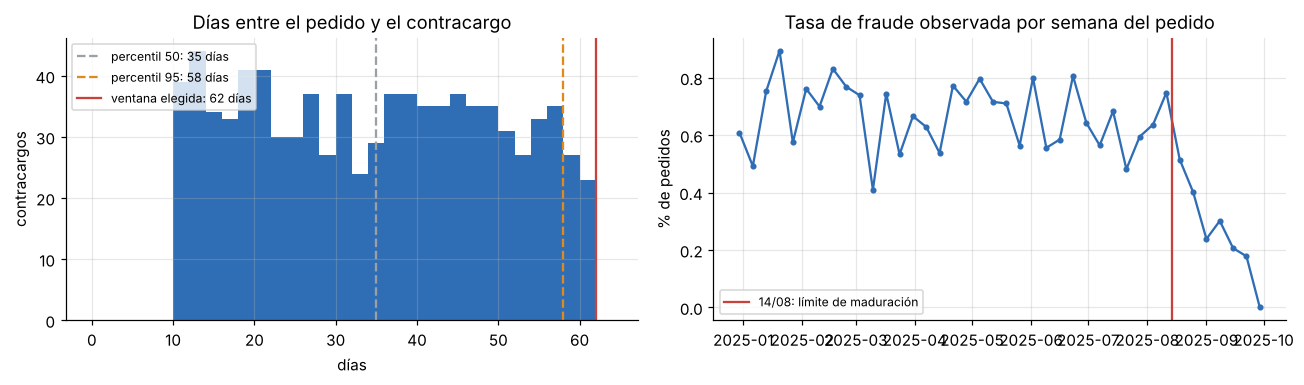

Demora: mínima 10 días, mediana 35, máxima 61. Ventana de maduración = 62 días.


In [18]:
con_cb = base[base.fecha_contracargo.notna()]
demora = (con_cb.fecha_contracargo - con_cb.fecha_hora.dt.normalize()).dt.days
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(demora, bins=range(0, 66, 2), color=AZUL)
ax[0].set(title="Días entre el pedido y el contracargo", xlabel="días", ylabel="contracargos")
for q, c in [(0.5, GRIS), (0.95, NARANJA)]:
    ax[0].axvline(demora.quantile(q), color=c, ls="--", label=f"percentil {int(q*100)}: {demora.quantile(q):.0f} días")
ax[0].axvline(MADURACION, color=ROJO, label=f"ventana elegida: {MADURACION} días"); ax[0].legend(fontsize=8)

semana = pob.groupby(pob.fecha_hora.dt.to_period("W").dt.start_time).fraude.mean() * 100
ax[1].plot(semana.index, semana.values, color=AZUL, marker="o", ms=3)
ax[1].axvline(FECHA_MADURA, color=ROJO, label=f"{FECHA_MADURA:%d/%m}: límite de maduración")
ax[1].set(title="Tasa de fraude observada por semana del pedido", ylabel="% de pedidos"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Demora: mínima {demora.min()} días, mediana {demora.median():.0f}, máxima {demora.max()}. Ventana de maduración = {MADURACION} días.")

**Lectura:** los contracargos llegan de forma pareja entre los 10 y los 61 días. A la derecha de la línea roja la tasa de fraude «baja», pero no porque haya menos fraude: **todavía no llegaron los reclamos**. Si se entrenara con esos pedidos, el modelo aprendería que los fraudes recientes son buenos.

### 3.2 Tasa de fraude con su intervalo de confianza

Con 0,7 % de positivos, un intervalo normal («más o menos dos errores estándar») funciona mal cerca de cero. Usamos el **intervalo de Wilson**.

In [19]:
from scipy import stats

def wilson(k, n, conf=0.95):
    """Intervalo de Wilson para una proporción k/n."""
    if n == 0: return (np.nan, np.nan)
    z = stats.norm.ppf(1 - (1 - conf) / 2); p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n); ancho = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - ancho, centro + ancho

k, n = int(maduros.fraude.sum()), len(maduros); lo, hi = wilson(k, n)
TASA = k / n
print(f"Tasa de fraude observada (pedidos aprobados con etiqueta madura): {TASA:.3%}  ·  IC 95 %: [{lo:.3%} ; {hi:.3%}]  ·  {k} fraudes en {n:,} pedidos")
print(f"Son unos {k / maduros.dia.nunique():.1f} fraudes por día entre {n / maduros.dia.nunique():.0f} pedidos diarios.")
print(f"Aparte: {int(maduros.no_recibida.sum())} contracargos por mercadería no recibida ({maduros.no_recibida.mean():.3%}).")

Tasa de fraude observada (pedidos aprobados con etiqueta madura): 0.671%  ·  IC 95 %: [0.624% ; 0.721%]  ·  726 fraudes en 108,231 pedidos
Son unos 3.2 fraudes por día entre 481 pedidos diarios.
Aparte: 70 contracargos por mercadería no recibida (0.065%).


La consigna habla de «alrededor del 0,8 %» y nosotros observamos **0,67 %**, con un intervalo que no llega a 0,8 %. Una explicación posible (que no podemos verificar con estos datos) es que **no todos los fraudes se reclaman**: si el titular no revisa su resumen, el fraude nunca aparece como contracargo. Lo declaramos como **límite**: la tasa observada es un piso de la real y el modelo aprende de los fraudes *reclamados*.

### 3.3 ¿Qué grupos de pedidos tienen más fraude?

Comparamos la tasa de fraude dentro y fuera de cada grupo con una **prueba chi cuadrado** (H0: la tasa es la misma). Como hacemos siete pruebas, usamos la corrección de **Bonferroni**: exigimos p < 0,05 / 7.

In [20]:
grupos = {
    "ráfaga: otro pedido del cliente en la última hora": maduros.rafaga == 1,
    "cuenta nueva (menos de 7 días)": maduros.cuenta_nueva_7d == 1,
    "correo con usuario genérico (u12345@)": maduros.email_generico == 1,
    "envío al exterior": maduros.envio_exterior == 1,
    "madrugada (0 a 6 h)": maduros.madrugada == 1,
    "dispositivo nunca visto": maduros.disp_nuevo == 1,
    "teléfono verificado": maduros.telefono_verificado == 1,
}
filas = []
for nombre, m in grupos.items():
    k1, n1, k0, n0 = maduros.fraude[m].sum(), m.sum(), maduros.fraude[~m].sum(), (~m).sum()
    _, p_valor, _, _ = stats.chi2_contingency([[k1, n1 - k1], [k0, n0 - k0]])
    (l1, h1), (l0, h0) = wilson(k1, n1), wilson(k0, n0)
    filas.append({"grupo": nombre, "pedidos en el grupo": n1, "% del total": n1 / len(maduros),
                  "tasa en el grupo": k1 / n1, "IC 95 % grupo": f"[{l1:.2%} ; {h1:.2%}]",
                  "tasa en el resto": k0 / n0, "IC 95 % resto": f"[{l0:.2%} ; {h0:.2%}]",
                  "veces más": (k1 / n1) / (k0 / n0), "p-valor": p_valor, "significativo (Bonferroni)": p_valor < 0.05 / len(grupos)})
comparacion_grupos = pd.DataFrame(filas).sort_values("veces más", ascending=False)
comparacion_grupos.style.format({"% del total": "{:.1%}", "tasa en el grupo": "{:.2%}", "tasa en el resto": "{:.2%}", "veces más": "{:.1f}", "p-valor": "{:.1e}", "pedidos en el grupo": "{:,}"})

,grupo,pedidos en el grupo,% del total,tasa en el grupo,IC 95 % grupo,tasa en el resto,IC 95 % resto,veces más,p-valor,significativo (Bonferroni)
0,ráfaga: otro pedido del cliente en la última hora,"3,749",3.5%,14.96%,[13.86% ; 16.14%],0.16%,[0.14% ; 0.18%],94.8,0.0e+00,True
1,cuenta nueva (menos de 7 días),"7,408",6.8%,1.48%,[1.23% ; 1.79%],0.61%,[0.56% ; 0.66%],2.4,1.1e-18,True
2,correo con usuario genérico (u12345@),"8,031",7.4%,0.98%,[0.79% ; 1.22%],0.65%,[0.60% ; 0.70%],1.5,4.7e-04,True
3,envío al exterior,"3,843",3.6%,0.86%,[0.61% ; 1.20%],0.66%,[0.62% ; 0.71%],1.3,1.8e-01,False
4,madrugada (0 a 6 h),"27,134",25.1%,0.79%,[0.69% ; 0.90%],0.63%,[0.58% ; 0.69%],1.2,6.8e-03,True
6,teléfono verificado,"67,523",62.4%,0.69%,[0.63% ; 0.75%],0.64%,[0.57% ; 0.73%],1.1,4.2e-01,False
5,dispositivo nunca visto,"56,676",52.4%,0.23%,[0.19% ; 0.27%],1.16%,[1.07% ; 1.25%],0.2,2.4e-77,True


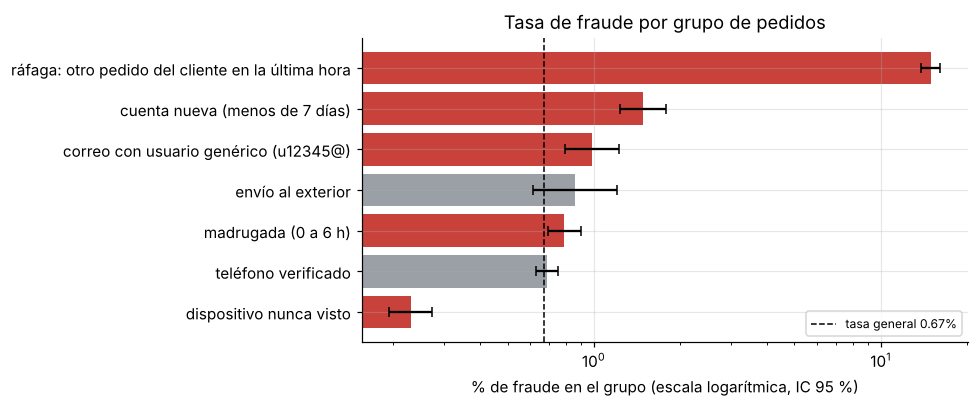

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.8))
cg = comparacion_grupos.iloc[::-1]
err = np.array([[r["tasa en el grupo"] - wilson(r["tasa en el grupo"] * r["pedidos en el grupo"], r["pedidos en el grupo"])[0],
                 wilson(r["tasa en el grupo"] * r["pedidos en el grupo"], r["pedidos en el grupo"])[1] - r["tasa en el grupo"]] for _, r in cg.iterrows()]).T * 100
ax.barh(cg.grupo, cg["tasa en el grupo"] * 100, xerr=err, color=[ROJO if s else GRIS for s in cg["significativo (Bonferroni)"]], capsize=3)
ax.axvline(TASA * 100, color="k", ls="--", lw=1, label=f"tasa general {TASA:.2%}")
ax.set(xscale="log", xlabel="% de fraude en el grupo (escala logarítmica, IC 95 %)", title="Tasa de fraude por grupo de pedidos"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Conclusión y límites de la prueba:**

* La señal más fuerte, lejos, es la **ráfaga**: cuando el mismo cliente ya hizo otro pedido en la última hora, la tasa de fraude es de ~15 %, casi **100 veces** la del resto. La **cuenta nueva** la multiplica por 2,4 y el **correo genérico** por 1,5; la **madrugada** también da diferencia significativa, aunque chica (1,2 veces).
* **Dos hipótesis no se sostienen**: ni el **teléfono verificado** ni el **envío al exterior** muestran una diferencia que resista la corrección por pruebas múltiples. Son resultados negativos y los dejamos a la vista: verificar el teléfono no protege, y «exterior» por sí solo no alcanza para frenar.
* Un caso que contradice la intuición: el **dispositivo nunca visto tiene menos fraude** que el resto. La mitad de los pedidos son el primer uso de un dispositivo (clientes que compran poco), mientras que el fraude se concentra en ráfagas cuyos pedidos 2.º y 3.º repiten el mismo dispositivo. Es una advertencia: las señales se pisan entre sí y una comparación de a una no reemplaza al modelo.
* Son **asociaciones, no causas**: la cuenta nueva no «produce» fraude; es un rasgo de los pedidos que eligen quienes defraudan.
* **Límite:** estas comparaciones usan todos los pedidos maduros, incluido el tramo que después usamos de prueba. Por eso **no** las usamos para fijar los pesos de la regla de referencia de la sección 4 (que se fijan solo con entrenamiento).

### 3.4 ¿Los fraudes son más caros?

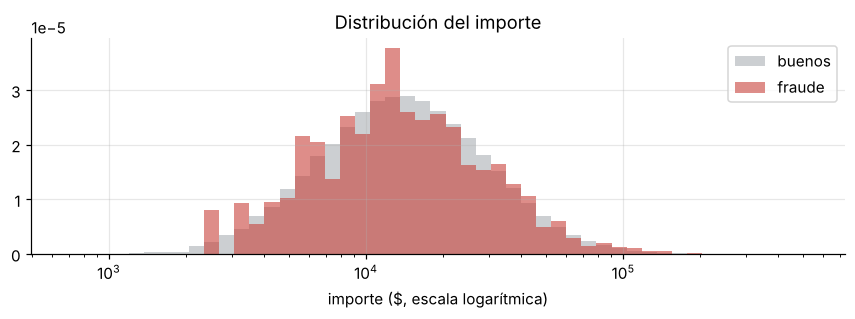

Mediana del importe: fraude $24,699 vs buenos $24,312  ·  Mann-Whitney (fraude > buenos): p = 3.1e-01
El fraude es 0.67% de los pedidos pero 0.72% del monto.


In [22]:
imp_f, imp_b = maduros.loc[maduros.fraude == 1, "importe"], maduros.loc[maduros.fraude == 0, "importe"]
u = stats.mannwhitneyu(imp_f, imp_b, alternative="greater")
fig, ax = plt.subplots(figsize=(8, 3))
bins = np.logspace(np.log10(maduros.importe.min()), np.log10(maduros.importe.max()), 50)
ax.hist(imp_b, bins=bins, density=True, alpha=0.5, color=GRIS, label="buenos"); ax.hist(imp_f, bins=bins, density=True, alpha=0.6, color=ROJO, label="fraude")
ax.set(xscale="log", xlabel="importe ($, escala logarítmica)", title="Distribución del importe"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Mediana del importe: fraude ${imp_f.median():,.0f} vs buenos ${imp_b.median():,.0f}  ·  Mann-Whitney (fraude > buenos): p = {u.pvalue:.1e}")
print(f"El fraude es {k/n:.2%} de los pedidos pero {imp_f.sum() / maduros.importe.sum():.2%} del monto.")

**La hipótesis «el fraude se concentra en pedidos caros» no se sostiene**: la mediana es casi la misma y la prueba de Mann-Whitney no rechaza la igualdad. El fraude es 0,67 % de los pedidos y 0,72 % del monto. Consecuencia práctica: **revisar los pedidos más caros no sirve** como regla (lo comprobamos en la sección 4, donde es nuestra primera referencia).

## 4 · Modelado

**Qué tenés que resolver en tu caso:** Regresión logística, Random Forest y XGBoost con pesos; validación temporal con una ventana de maduración; PR-AUC y recall en la cola de 40.

Empezá por una referencia simple. Validá sin mirar el futuro y elegí la métrica por el costo del error, no por costumbre.

### 4.1 Validación temporal con ventana de maduración

Simulamos que **el modelo se pone en producción el 1/7/2025**. Ese día solo se conoce la etiqueta completa de los pedidos de hasta 62 días antes (30/4). Entonces:

| Tramo | Pedidos | Para qué |
| --- | --- | --- |
| Entrenamiento | 01/01 al 31/03 | Ajustar los modelos |
| Validación | 01/04 al 29/04 | Elegir modelo e hiperparámetros, calibrar y fijar umbrales |
| Brecha | 30/04 al 30/06 | **No se usa**: el 1/7 sus contracargos todavía no habían llegado |
| Prueba | 01/07 al 13/08 | Medir una sola vez, como si fuera el futuro |

La brecha no es un desperdicio: refleja que en la vida real el modelo siempre trabaja con **dos meses de atraso** en sus etiquetas.

In [23]:
FECHA_DESPLIEGUE = pd.Timestamp("2025-07-01")
FIN_ETIQUETAS = FECHA_DESPLIEGUE - pd.Timedelta(days=MADURACION)
ent = maduros[maduros.fecha_hora < "2025-04-01"].copy()
val = maduros[(maduros.fecha_hora >= "2025-04-01") & (maduros.fecha_hora < FIN_ETIQUETAS)].copy()
pru = maduros[maduros.fecha_hora >= FECHA_DESPLIEGUE].copy()
# control de fuga: ningún contracargo de entrenamiento o validación llegó después del despliegue simulado
assert (pd.concat([ent, val]).fecha_contracargo.dropna() < FECHA_DESPLIEGUE).all()
tramos = pd.DataFrame([(nombre, d.fecha_hora.min().date(), d.fecha_hora.max().date(), len(d), int(d.fraude.sum()), d.fraude.mean())
                       for nombre, d in [("entrenamiento", ent), ("validación", val), ("prueba", pru)]],
                      columns=["tramo", "desde", "hasta", "pedidos", "fraudes", "tasa"])
tramos.style.format({"tasa": "{:.2%}", "pedidos": "{:,}"})

,tramo,desde,hasta,pedidos,fraudes,tasa
0,entrenamiento,2025-01-01,2025-03-31,"43,615",296,0.68%
1,validación,2025-04-01,2025-04-29,"13,907",90,0.65%
2,prueba,2025-07-01,2025-08-13,"21,011",136,0.65%


### 4.2 Las métricas, elegidas por el costo del error

* **Recall en la cola de 40 por día** (la métrica principal): de todos los fraudes del período, ¿qué parte cae entre los 40 pedidos con más riesgo de cada día? Es exactamente lo que el equipo de revisión puede atender.
* **Precisión en la cola**: de los 40 que se revisan, ¿cuántos son fraude? Con ~3 fraudes por día, el techo es 3/40 ≈ 8 %: no esperamos precisiones altas.
* **Monto capturado**: el recall ponderado por importe, porque un contracargo de $200.000 duele más que uno de $5.000.
* **PR-AUC** (precisión promedio): resume todo el ranking sin elegir un umbral. Su referencia es la tasa de fraude (≈0,007): un puntaje al azar saca eso.
* **ROC-AUC** solo como dato secundario: con 0,7 % de positivos se ve alta aunque el modelo sea poco útil.
* **Fricción**: clientes buenos revisados o frenados por día.

In [24]:
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
CAPACIDAD = 40

def rango_diario(d, puntaje):
    return pd.Series(puntaje, index=d.index).groupby(d.dia).rank(ascending=False, method="first")

def evaluar(d, puntaje, k=CAPACIDAD, nombre=""):
    puntaje = np.asarray(puntaje, dtype=float); en_cola = rango_diario(d, puntaje).values <= k
    f = d.fraude.values == 1
    return {"modelo": nombre, "PR-AUC": average_precision_score(f, puntaje), "ROC-AUC": roc_auc_score(f, puntaje),
            f"recall en cola {k}": f[en_cola].sum() / f.sum(), f"precisión en cola {k}": f[en_cola].mean(),
            "monto capturado": d.importe.values[en_cola & f].sum() / d.importe.values[f].sum(),
            "buenos revisados por día": (en_cola & ~f).sum() / d.dia.nunique()}

FORMATO = {"PR-AUC": "{:.3f}", "ROC-AUC": "{:.3f}", "recall en cola 40": "{:.1%}", "precisión en cola 40": "{:.1%}", "monto capturado": "{:.1%}", "buenos revisados por día": "{:.1f}"}

### 4.3 Dos referencias simples

Antes de cualquier algoritmo, ¿qué tan lejos se llega sin modelo?

1. **Revisar los 40 pedidos más caros del día**: una regla razonable que podría estar usando hoy el equipo.
2. **Una regla de puntos**: 3 puntos por ráfaga y 1 por cada otra señal (cuenta nueva, correo genérico, envío al exterior, madrugada); se desempata por importe. Los pesos se eligen mirando **solo el tramo de entrenamiento**: si los eligiéramos con la sección 3 (que usa todos los pedidos maduros, incluida la prueba) la regla tendría una ventaja injusta.

In [25]:
señales = ["rafaga", "cuenta_nueva_7d", "email_generico", "envio_exterior", "madrugada"]
display(pd.DataFrame({c: {"tasa si está": ent.loc[ent[c] == 1, "fraude"].mean(), "tasa si no está": ent.loc[ent[c] == 0, "fraude"].mean()} for c in señales}).T
        .assign(**{"veces más": lambda t: t["tasa si está"] / t["tasa si no está"]}).style.format({"tasa si está": "{:.2%}", "tasa si no está": "{:.2%}", "veces más": "{:.1f}"})
        .set_caption("Las señales de la regla, medidas SOLO en entrenamiento (enero a marzo)"))

def puntaje_reglas(d):
    return (3 * d.rafaga + d.cuenta_nueva_7d + d.email_generico + d.envio_exterior + d.madrugada) + d.log_importe / 100

referencias = pd.DataFrame([evaluar(val, val.importe, nombre="los 40 más caros"), evaluar(val, puntaje_reglas(val), nombre="regla de puntos")])
referencias.style.format(FORMATO)

,tasa si está,tasa si no está,veces más
rafaga,14.80%,0.18%,83.1
cuenta_nueva_7d,1.51%,0.62%,2.5
email_generico,1.16%,0.64%,1.8
envio_exterior,1.10%,0.66%,1.7
madrugada,0.79%,0.64%,1.2


,modelo,PR-AUC,ROC-AUC,recall en cola 40,precisión en cola 40,monto capturado,buenos revisados por día
0,los 40 más caros,0.008,0.555,12.2%,0.9%,32.5%,39.6
1,regla de puntos,0.142,0.930,81.1%,6.3%,76.7%,37.5


La regla del importe **no sirve**: captura poco más que el azar (40 de ~480 pedidos diarios es un 8 %). La **regla de puntos ya captura la mayoría de los fraudes**, porque la ráfaga es una señal muy fuerte. Esa es la vara que el modelo tiene que superar: si no la mejora claramente, conviene la regla.

### 4.4 Tres algoritmos con pesos para el desbalance

* **Regresión logística** con `class_weight="balanced"`: cada fraude pesa como ~150 pedidos buenos.
* **Random Forest** con `class_weight="balanced_subsample"` y hojas de al menos 20 pedidos para no memorizar.
* **XGBoost** con `scale_pos_weight`; probamos tres pesos y dos profundidades, y elegimos en validación.

A XGBoost lo probamos además con un **conjunto parsimonioso de variables**: sacamos las que no tienen una relación plausible con el fraude o que la sección 3 descartó (provincia, tipo de dispositivo, fin de semana, hora exacta —queda la marca de madrugada—, teléfono verificado y correo corporativo). Menos variables es un contrato más corto, menos cosas que se pueden romper y menos ruido para aprender. Decide la validación.

El preprocesamiento va **dentro del pipeline**: la mediana para imputar y la escala se aprenden solo con entrenamiento.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier
SEMILLA = 7

VARIABLES_PARSIMONIA = [v for v in VARIABLES if v not in ("provincia", "tipo", "fin_de_semana", "hora", "telefono_verificado", "email_corporativo")]

def preprocesador(variables=VARIABLES):
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)), ("escalar", StandardScaler())]), [v for v in NUM if v in variables]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), [v for v in CAT if v in variables])])

peso_fraude = (1 - ent.fraude.mean()) / ent.fraude.mean()
candidatos = {
    "regresión logística": LogisticRegression(class_weight="balanced", C=0.1, max_iter=3000),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample", n_jobs=-1, random_state=SEMILLA),
}
COLUMNAS = {"regresión logística": VARIABLES, "random forest": VARIABLES}
for conjunto, cols in [("todas", VARIABLES), ("parsimonioso", VARIABLES_PARSIMONIA)]:
    for spw in [1, 10, round(peso_fraude)]:
        for prof in [3, 4]:
            nombre = f"xgboost ({conjunto}, peso {spw}, prof. {prof})"
            candidatos[nombre] = XGBClassifier(n_estimators=300, max_depth=prof, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                                               reg_lambda=5, scale_pos_weight=spw, eval_metric="aucpr", n_jobs=-1, random_state=SEMILLA)
            COLUMNAS[nombre] = cols

def puntuar(nombre, d):
    return modelos[nombre].predict_proba(d[COLUMNAS[nombre]])[:, 1]

modelos, res_val, tiempos = {}, [], {}
for nombre, est in candidatos.items():
    t0 = time.time(); modelos[nombre] = Pipeline([("prep", preprocesador(COLUMNAS[nombre])), ("modelo", est)]).fit(ent[COLUMNAS[nombre]], ent.fraude)
    tiempos[nombre] = time.time() - t0
    res_val.append({**evaluar(val, puntuar(nombre, val), nombre=nombre), "variables": len(COLUMNAS[nombre]), "segundos de entrenamiento": tiempos[nombre]})
res_val = pd.concat([referencias, pd.DataFrame(res_val)], ignore_index=True)
res_val.style.format({**FORMATO, "segundos de entrenamiento": "{:.1f}", "variables": "{:.0f}"}).highlight_max(subset=["PR-AUC", "recall en cola 40"], color="#d6eaf8")

,modelo,PR-AUC,ROC-AUC,recall en cola 40,precisión en cola 40,monto capturado,buenos revisados por día,variables,segundos de entrenamiento
0,los 40 más caros,0.008,0.555,12.2%,0.9%,32.5%,39.6,nan,nan
1,regla de puntos,0.142,0.930,81.1%,6.3%,76.7%,37.5,nan,nan
2,regresión logística,0.103,0.925,80.0%,6.2%,78.3%,37.5,22,0.2
3,random forest,0.112,0.912,85.6%,6.6%,81.9%,37.3,22,5.0
4,"xgboost (todas, peso 1, prof. 3)",0.114,0.936,86.7%,6.7%,85.1%,37.3,22,0.6
5,"xgboost (todas, peso 1, prof. 4)",0.116,0.931,85.6%,6.6%,81.9%,37.3,22,0.7
6,"xgboost (todas, peso 10, prof. 3)",0.112,0.927,85.6%,6.6%,81.9%,37.3,22,0.7
7,"xgboost (todas, peso 10, prof. 4)",0.114,0.925,86.7%,6.7%,83.2%,37.3,22,0.7
8,"xgboost (todas, peso 146, prof. 3)",0.122,0.925,85.6%,6.6%,80.0%,37.3,22,0.7
9,"xgboost (todas, peso 146, prof. 4)",0.112,0.927,84.4%,6.6%,77.7%,37.4,22,0.6


In [27]:
xgb_val = res_val[res_val.modelo.str.startswith("xgboost")].sort_values(["PR-AUC", "variables"], ascending=[False, True])
MEJOR_XGB = xgb_val.modelo.iloc[0]
VARIABLES_MODELO = COLUMNAS[MEJOR_XGB]
finalistas = ["regla de puntos", "regresión logística", "random forest", MEJOR_XGB]
print("Mejor configuración de XGBoost en validación:", MEJOR_XGB)
print(f"Usa {len(VARIABLES_MODELO)} variables: {', '.join(VARIABLES_MODELO)}")
res_val[res_val.modelo.isin(finalistas)].style.format({**FORMATO, "segundos de entrenamiento": "{:.1f}", "variables": "{:.0f}"})

Mejor configuración de XGBoost en validación: xgboost (parsimonioso, peso 10, prof. 3)
Usa 16 variables: log_importe, cantidad_items, cuotas, madrugada, envio_exterior, antig_cuenta_dias, disp_faltante, disp_antig_dias, disp_pedidos_previos, email_generico, email_ya_usado, cli_pedidos_previos, min_desde_anterior, cli_pedidos_1h, cli_pedidos_24h, metodo_pago


,modelo,PR-AUC,ROC-AUC,recall en cola 40,precisión en cola 40,monto capturado,buenos revisados por día,variables,segundos de entrenamiento
1,regla de puntos,0.142,0.930,81.1%,6.3%,76.7%,37.5,nan,nan
2,regresión logística,0.103,0.925,80.0%,6.2%,78.3%,37.5,22,0.2
3,random forest,0.112,0.912,85.6%,6.6%,81.9%,37.3,22,5.0
12,"xgboost (parsimonioso, peso 10, prof. 3)",0.132,0.928,86.7%,6.7%,85.1%,37.3,16,0.5


### 4.5 Controles de fuga: ni variables ni etiquetas del futuro

**Control 1 · Prueba de «punto en el tiempo».** Recalculamos todas las variables con los datos cortados al 1/6/2025, como si fuera ese día, y comparamos con las variables calculadas con todos los datos. Si alguna variable usara información posterior, los pedidos anteriores al corte cambiarían de valor.

In [28]:
CORTE = pd.Timestamp("2025-06-01")
cols_base = list(P.columns) + [c for c in C.columns if c != "id_pedido"] + [c for c in CL.columns if c != "id_cliente"] + [c for c in DV.columns if c != "id_dispositivo"]
truncada = construir_variables(base.loc[base.fecha_hora < CORTE, cols_base]).set_index("id_pedido")[NUM]
completa = base.set_index("id_pedido").loc[truncada.index, NUM]
distintas = {c: int((~np.isclose(truncada[c].fillna(-1), completa[c].fillna(-1))).sum()) for c in NUM}
assert sum(distintas.values()) == 0, f"Hay variables que miran el futuro: {distintas}"
print(f"OK: las {len(NUM)} variables numéricas dan exactamente lo mismo para los {len(truncada):,} pedidos anteriores al {CORTE:%d/%m/%Y}, con o sin los datos posteriores.")

OK: las 19 variables numéricas dan exactamente lo mismo para los 79,153 pedidos anteriores al 01/06/2025, con o sin los datos posteriores.


**Control 2 · ¿Qué pasa si se entrena con etiquetas que no maduraron?** Es el error típico de este caso: el 1/7 entrenar con todos los pedidos hasta el 30/6, tomando como «bueno» todo pedido que todavía no tiene contracargo.

In [29]:
inmaduro = maduros[maduros.fecha_hora < FECHA_DESPLIEGUE].copy()
inmaduro["fraude_visible_al_1_7"] = ((inmaduro.fraude == 1) & (inmaduro.fecha_contracargo < FECHA_DESPLIEGUE)).astype(int)
print(f"Fraudes reales hasta el 30/6: {inmaduro.fraude.sum()} · visibles el 1/7: {inmaduro.fraude_visible_al_1_7.sum()} → "
      f"{1 - inmaduro.fraude_visible_al_1_7.sum() / inmaduro.fraude.sum():.0%} de los fraudes quedan etiquetados como buenos")
m_inmaduro = Pipeline([("prep", preprocesador(VARIABLES_MODELO)), ("modelo", XGBClassifier(**candidatos[MEJOR_XGB].get_params()))]).fit(inmaduro[VARIABLES_MODELO], inmaduro.fraude_visible_al_1_7)
control_madurez = pd.DataFrame([
    evaluar(pru, puntuar(MEJOR_XGB, pru), nombre="correcto: entrena hasta el 31/3, etiquetas maduras"),
    evaluar(pru, m_inmaduro.predict_proba(pru[VARIABLES_MODELO])[:, 1], nombre="error: entrena hasta el 30/6 con etiquetas inmaduras"),
])
control_madurez.style.format(FORMATO).set_caption(f"{MEJOR_XGB}, medido en el tramo de prueba")

Fraudes reales hasta el 30/6: 590 · visibles el 1/7: 481 → 18% de los fraudes quedan etiquetados como buenos


,modelo,PR-AUC,ROC-AUC,recall en cola 40,precisión en cola 40,monto capturado,buenos revisados por día
0,"correcto: entrena hasta el 31/3, etiquetas maduras",0.154,0.933,86.8%,6.7%,84.1%,37.3
1,error: entrena hasta el 30/6 con etiquetas inmaduras,0.127,0.921,86.8%,6.7%,83.4%,37.3


**Lectura:** el modelo entrenado con etiquetas inmaduras usa **el doble de datos** y aun así ordena peor: su PR-AUC cae de forma clara, porque aprendió que los pedidos de mayo y junio con perfil de fraude son «buenos». En la cola de 40 el daño no se nota en este caso (las ráfagas son tan evidentes que entran igual), pero sí en el resto del ranking, que es lo que importa cuando la capacidad baja o el fraude se vuelve menos obvio. Más datos no compensan etiquetas equivocadas: la brecha de 62 días es parte del diseño, también en cada reentrenamiento.

### 4.6 Prueba: una sola medición, con intervalos

Medimos los finalistas en el tramo de prueba (julio y agosto, nunca visto). Como hay pocos fraudes (~140), calculamos **intervalos de confianza por bootstrap remuestreando días** (los pedidos del mismo día no son independientes: una ráfaga cae entera en un día).

In [30]:
def bootstrap_dias(d, puntaje, n=500, semilla=SEMILLA):
    d = d.assign(_s=np.asarray(puntaje)); d["_cola"] = rango_diario(d, d._s).values <= CAPACIDAD
    dias = d.dia.unique(); grupos_dia = {k: v for k, v in d.groupby("dia")}; rng = np.random.default_rng(semilla); out = []
    for _ in range(n):
        m = pd.concat([grupos_dia[x] for x in rng.choice(dias, len(dias))])
        out.append((average_precision_score(m.fraude, m._s), m.loc[m._cola, "fraude"].sum() / max(m.fraude.sum(), 1)))
    return np.array(out)

puntajes_prueba = {"regla de puntos": puntaje_reglas(pru).values}
for nombre in finalistas[1:]: puntajes_prueba[nombre] = puntuar(nombre, pru)
filas, boot = [], {}
for nombre, s in puntajes_prueba.items():
    boot[nombre] = bootstrap_dias(pru, s); r = evaluar(pru, s, nombre=nombre)
    r["IC 95 % PR-AUC"] = "[{:.3f} ; {:.3f}]".format(*np.percentile(boot[nombre][:, 0], [2.5, 97.5]))
    r["IC 95 % recall cola"] = "[{:.0%} ; {:.0%}]".format(*np.percentile(boot[nombre][:, 1], [2.5, 97.5])); filas.append(r)
res_prueba = pd.DataFrame(filas)
res_prueba.style.format(FORMATO)

,modelo,PR-AUC,ROC-AUC,recall en cola 40,precisión en cola 40,monto capturado,buenos revisados por día,IC 95 % PR-AUC,IC 95 % recall cola
0,regla de puntos,0.129,0.931,86.8%,6.7%,82.0%,37.3,[0.101 ; 0.166],[81% ; 91%]
1,regresión logística,0.148,0.914,79.4%,6.1%,73.2%,37.5,[0.108 ; 0.204],[73% ; 85%]
2,random forest,0.139,0.935,86.8%,6.7%,84.5%,37.3,[0.113 ; 0.172],[81% ; 92%]
3,"xgboost (parsimonioso, peso 10, prof. 3)",0.154,0.933,86.8%,6.7%,84.1%,37.3,[0.127 ; 0.196],[81% ; 91%]


In [31]:
# ¿La diferencia entre los modelos es real? Bootstrap pareado: mismos días remuestreados para los dos puntajes.
def dif_pareada(d, s1, s2, n=500, semilla=SEMILLA):
    d = d.assign(_a=s1, _b=s2); d["_ca"] = rango_diario(d, d._a).values <= CAPACIDAD; d["_cb"] = rango_diario(d, d._b).values <= CAPACIDAD
    dias = d.dia.unique(); gd = {k: v for k, v in d.groupby("dia")}; rng = np.random.default_rng(semilla); out = []
    for _ in range(n):
        m = pd.concat([gd[x] for x in rng.choice(dias, len(dias))]); f = m.fraude.sum()
        out.append((average_precision_score(m.fraude, m._a) - average_precision_score(m.fraude, m._b), (m.loc[m._ca, "fraude"].sum() - m.loc[m._cb, "fraude"].sum()) / f))
    return np.array(out)

comparaciones = []
for a_, b_n in [(MEJOR_XGB, "regla de puntos"), ("random forest", "regla de puntos"), ("regresión logística", "regla de puntos"), (MEJOR_XGB, "regresión logística")]:
    dd = dif_pareada(pru, puntajes_prueba[a_], puntajes_prueba[b_n])
    comparaciones.append({"comparación": f"{a_} − {b_n}", "Δ PR-AUC": dd[:, 0].mean(), "IC 95 % Δ PR-AUC": "[{:+.3f} ; {:+.3f}]".format(*np.percentile(dd[:, 0], [2.5, 97.5])),
                          "Δ recall cola": dd[:, 1].mean(), "IC 95 % Δ recall": "[{:+.1%} ; {:+.1%}]".format(*np.percentile(dd[:, 1], [2.5, 97.5])),
                          "¿el IC del recall excluye el 0?": bool(np.percentile(dd[:, 1], 2.5) > 0 or np.percentile(dd[:, 1], 97.5) < 0)})
comparaciones = pd.DataFrame(comparaciones)
print(f"Fraudes de la prueba en ráfaga (otro pedido del mismo cliente en la última hora): {pru.loc[pru.fraude == 1, 'rafaga'].mean():.0%} "
      f"({int(pru.loc[pru.fraude == 1, 'rafaga'].sum())} de {int(pru.fraude.sum())})")
comparaciones.style.format({"Δ PR-AUC": "{:+.3f}", "Δ recall cola": "{:+.1%}"})

Fraudes de la prueba en ráfaga (otro pedido del mismo cliente en la última hora): 80% (109 de 136)


,comparación,Δ PR-AUC,IC 95 % Δ PR-AUC,Δ recall cola,IC 95 % Δ recall,¿el IC del recall excluye el 0?
0,"xgboost (parsimonioso, peso 10, prof. 3) − regla de puntos",+0.027,[-0.001 ; +0.060],+0.0%,[-3.4% ; +3.8%],False
1,random forest − regla de puntos,+0.009,[-0.025 ; +0.040],+0.1%,[-4.0% ; +4.3%],False
2,regresión logística − regla de puntos,+0.019,[-0.025 ; +0.072],-7.4%,[-12.6% ; -3.3%],True
3,"xgboost (parsimonioso, peso 10, prof. 3) − regresión logística",+0.008,[-0.040 ; +0.054],+7.4%,[+2.5% ; +13.3%],True


**El resultado más importante de la sección, y es negativo:** en la cola de 40, **ningún algoritmo supera a la regla de puntos de forma demostrable**. XGBoost y Random Forest capturan exactamente lo mismo que la regla (diferencia 0, con un intervalo de ±4 puntos) y la regresión logística captura menos. En PR-AUC, que mira todo el ranking, XGBoost parsimonioso queda arriba de la regla (+0,03), pero el intervalo toca el cero: es un **indicio**, no una prueba.

¿Por qué? Porque casi todo el fraude de Vidriera tiene una firma muy simple: **la ráfaga**. Cuatro de cada cinco fraudes de la prueba son pedidos de un cliente que ya había comprado en la última hora, y la regla los pone a todos en la cola. Fuera de las ráfagas queda poco fraude y con señales débiles.

Lo que sí cambia todo es **revisar en orden de riesgo** en vez de por importe: de ~12 % a ~85 % de los fraudes capturados con la misma gente.

### 4.7 ¿Cuánto rinde cada tamaño de cola?

La capacidad de 40 es un dato de hoy. La curva muestra qué se ganaría o perdería con más o menos analistas.

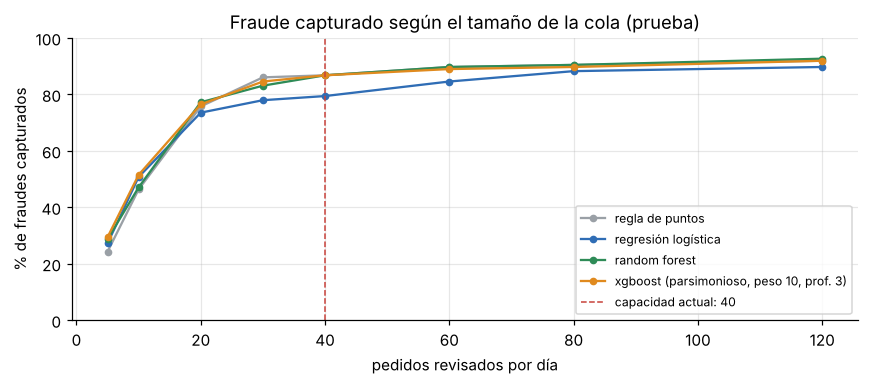

In [32]:
ks = [5, 10, 20, 30, 40, 60, 80, 120]
fig, ax = plt.subplots(figsize=(8, 3.6))
for (nombre, s), c in zip(puntajes_prueba.items(), [GRIS, AZUL, VERDE, NARANJA]):
    ax.plot(ks, [evaluar(pru, s, k=k)[f"recall en cola {k}"] * 100 for k in ks], marker="o", ms=4, color=c, label=nombre)
ax.axvline(CAPACIDAD, color=ROJO, ls="--", lw=1, label="capacidad actual: 40")
ax.set(xlabel="pedidos revisados por día", ylabel="% de fraudes capturados", title="Fraude capturado según el tamaño de la cola (prueba)", ylim=(0, 100)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.8 Del puntaje a la decisión: calibración y dos umbrales

Para elegir **cuánto riesgo justifica frenar un pedido** hace falta una probabilidad que signifique lo que dice: si el modelo dice 10 %, que de cada 100 pedidos así 10 sean fraude. Los pesos del desbalance inflan las probabilidades, así que **calibramos** con el tramo de validación (escalado de Platt: una regresión logística sobre el puntaje). La calibración no cambia el orden, solo la escala.

Elegimos XGBoost como modelo de trabajo (en la sección 8 explicamos por qué, si empata con la regla).

In [33]:
MODELO_ELEGIDO = MEJOR_XGB
modelo_sim = modelos[MODELO_ELEGIDO]                 # el modelo «desplegado» el 1/7 (entrenado con enero a marzo)

def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

platt = LogisticRegression(C=1e6).fit(logit(modelo_sim.predict_proba(val[VARIABLES_MODELO])[:, 1]).reshape(-1, 1), val.fraude)
def probabilidad(modelo, calibrador, d):
    return calibrador.predict_proba(logit(modelo.predict_proba(d[VARIABLES_MODELO])[:, 1]).reshape(-1, 1))[:, 1]

val["p"] = probabilidad(modelo_sim, platt, val); pru["p"] = probabilidad(modelo_sim, platt, pru)
cortes = [0, .5, .9, .97, .99, .997, 1]
cal_tabla = (pru.assign(tramo=pd.qcut(pru.p.rank(method="first"), cortes, labels=[f"{a:.1%}–{b:.1%}" for a, b in zip(cortes[:-1], cortes[1:])]))
             .groupby("tramo", observed=True).agg(pedidos=("p", "size"), probabilidad_media=("p", "mean"), fraudes=("fraude", "sum"), tasa_observada=("fraude", "mean")))
cal_tabla["IC 95 %"] = [("[{:.1%} ; {:.1%}]".format(*wilson(r.fraudes, r.pedidos))) for r in cal_tabla.itertuples()]
print(f"Brier en prueba: modelo {brier_score_loss(pru.fraude, pru.p):.5f} · predecir siempre la tasa media {brier_score_loss(pru.fraude, np.full(len(pru), ent.fraude.mean())):.5f}")
cal_tabla.style.format({"probabilidad_media": "{:.2%}", "tasa_observada": "{:.2%}"}).set_caption("Calibración en prueba, por percentil de riesgo")

Brier en prueba: modelo 0.00576 · predecir siempre la tasa media 0.00643


,pedidos,probabilidad_media,fraudes,tasa_observada,IC 95 %
tramo,,,,,
0.0%–50.0%,10506,0.07%,5,0.05%,[0.0% ; 0.1%]
50.0%–90.0%,8404,0.28%,11,0.13%,[0.1% ; 0.2%]
90.0%–97.0%,1470,1.92%,26,1.77%,[1.2% ; 2.6%]
97.0%–99.0%,420,11.07%,56,13.33%,[10.4% ; 16.9%]
99.0%–99.7%,147,18.31%,24,16.33%,[11.2% ; 23.1%]
99.7%–100.0%,64,27.37%,14,21.88%,[13.5% ; 33.4%]


La calibración es buena donde se toman las decisiones (el 10 % de mayor riesgo): la probabilidad media cae dentro del intervalo de la tasa observada. En el tramo medio-bajo el modelo **sobreestima un poco** (dice 0,28 % y se observa 0,13 %), sin efecto práctico: esos pedidos se aprueban igual. Lo anotamos y queda en el plan de monitoreo. Un dato clave: **ningún tramo supera el ~25 % de fraude**. Incluso los pedidos más riesgosos son, en su mayoría, de clientes buenos. Eso condiciona el umbral de bloqueo.

**Los costos (supuestos que hay que validar con Vidriera, ver sección 8):**

| Resultado | Costo |
| --- | --- |
| Fraude aprobado | importe del pedido (la mercadería se pierde) + comisión del contracargo |
| Fraude revisado | el analista lo detecta el 85 % de las veces; el 15 % restante cuesta como un fraude aprobado |
| Fraude bloqueado | 0 |
| Cliente bueno revisado | 0 en plata (se demora unas horas el despacho) |
| Cliente bueno bloqueado | se le pide verificar identidad y el 40 % abandona: se pierde el margen (30 %) |

De ahí salen, sin mirar los datos de prueba, **dos umbrales** sobre la probabilidad calibrada:

* **Umbral de bloqueo**: bloquear conviene más que revisar cuando `p × (1 − efectividad) × (importe + comisión) > (1 − p) × abandono × margen × importe`.
* **Umbral de revisión**: el que, en validación, deja en promedio 36 pedidos retenidos por día (el 90 % de la capacidad), para dejar margen a los días con más pedidos.

**Cómo funciona en tiempo real.** Cada pedido recibe su decisión en milisegundos, al momento de pagar: *aprobar* (se despacha), *bloquear* (se frena y se pide verificación al cliente) o *retener para revisión*. Los retenidos esperan en una **cola ordenada por riesgo** (supuesto: el despacho sale al día hábil siguiente, así que retener unas horas no demora la entrega). El equipo revisa los 40 de mayor riesgo del día. **Regla de desborde:** si un día hay más de 40 retenidos, los que no entran se bloquean si su probabilidad supera el punto en que bloquear conviene más que aprobar; si no, se liberan.

In [34]:
COSTOS = {"comision_contracargo": 3000, "margen": 0.30, "abandono_si_se_frena": 0.40, "efectividad_revision": 0.85}
IMPORTE_TIPICO = float(ent.importe.median())

def umbrales_por_costo(c=COSTOS, importe=IMPORTE_TIPICO):
    am, f = c["abandono_si_se_frena"] * c["margen"], 1 + c["comision_contracargo"] / importe
    return {"bloquear_antes_que_revisar": am / (am + (1 - c["efectividad_revision"]) * f), "bloquear_antes_que_aprobar": am / (am + f)}

def umbral_revision(d, p, capacidad=CAPACIDAD, ocupacion=0.9):
    """Probabilidad a partir de la cual entran, en promedio por día, capacidad × ocupacion pedidos."""
    return float(np.quantile(p, 1 - capacidad * ocupacion * d.dia.nunique() / len(d)))

def aplicar_politica(d, p, t_rev, t_bloq, t_desborde, capacidad=CAPACIDAD):
    """Decisión en tiempo real con dos umbrales y cola de revisión por prioridad, con regla de desborde."""
    d = d.assign(p=np.asarray(p))
    d["decision"] = np.where(d.p >= t_bloq, "bloquear", np.where(d.p >= t_rev, "revisar", "aprobar"))
    retenidos = d[d.decision == "revisar"]
    prioridad = retenidos.groupby("dia").p.rank(ascending=False, method="first")
    no_entran = prioridad[prioridad > capacidad].index
    d.loc[no_entran, "decision"] = np.where(d.loc[no_entran, "p"] >= t_desborde, "bloquear", "aprobar")
    d["desbordado"] = d.index.isin(no_entran)
    return d

def costo_pedidos(d, decision, c=COSTOS):
    perdida = d.importe + c["comision_contracargo"]; f = d.fraude == 1
    return np.select([f & (decision == "aprobar"), f & (decision == "revisar"), ~f & (decision == "bloquear")],
                     [perdida, (1 - c["efectividad_revision"]) * perdida, c["abandono_si_se_frena"] * c["margen"] * d.importe], 0.0)

def resumen_politica(d, decision, nombre, c=COSTOS):
    f = d.fraude == 1; dias = d.dia.nunique(); costo = costo_pedidos(d, decision, c)
    capt = f & ((decision == "bloquear") | (decision == "revisar"))
    return {"política": nombre, "fraudes capturados": capt.sum() / f.sum(), "monto de fraude capturado": d.importe[capt].sum() / d.importe[f].sum(),
            "revisados por día": (decision == "revisar").sum() / dias, "bloqueados por día": (decision == "bloquear").sum() / dias,
            "clientes buenos frenados por día": (~f & (decision != "aprobar")).sum() / dias,
            "costo por día ($)": costo.sum() / dias}

U = umbrales_por_costo(); T_BLOQUEO, T_DESBORDE = U["bloquear_antes_que_revisar"], U["bloquear_antes_que_aprobar"]
T_REVISION = umbral_revision(val, val.p)
print(f"Umbral de bloqueo:   p ≥ {T_BLOQUEO:.1%}   (bloquear conviene más que revisar)")
print(f"Umbral de revisión:  p ≥ {T_REVISION:.2%}  (llena ~36 lugares por día en validación)")
print(f"Regla de desborde:   los retenidos que no entran en los 40 del día se bloquean si p ≥ {T_DESBORDE:.1%}; si no, se liberan")
print(f"En validación, {(val.p >= T_BLOQUEO).sum()} pedidos superan el umbral de bloqueo.")

Umbral de bloqueo:   p ≥ 41.6%   (bloquear conviene más que revisar)
Umbral de revisión:  p ≥ 0.81%  (llena ~36 lugares por día en validación)
Regla de desborde:   los retenidos que no entran en los 40 del día se bloquean si p ≥ 9.7%; si no, se liberan
En validación, 1 pedidos superan el umbral de bloqueo.


**Chequeo en validación**: ¿el umbral de bloqueo que sale de la fórmula es el mejor? Probamos varios con la misma política.

In [35]:
grilla = []
for t in [1.01, 0.6, T_BLOQUEO, 0.3, 0.2, 0.15, 0.1, 0.05]:
    dv_ = aplicar_politica(val, val.p, T_REVISION, t, T_DESBORDE)
    grilla.append({**resumen_politica(dv_, dv_.decision.values, f"bloquear si p ≥ {t:.0%}" if t <= 1 else "no bloquear nunca"), "umbral": t})
pd.DataFrame(grilla).style.format({"fraudes capturados": "{:.1%}", "monto de fraude capturado": "{:.1%}", "revisados por día": "{:.1f}", "bloqueados por día": "{:.1f}",
                                   "clientes buenos frenados por día": "{:.1f}", "costo por día ($)": "${:,.0f}", "umbral": "{:.2f}"}).highlight_min(subset=["costo por día ($)"], color="#d6eaf8")

,política,fraudes capturados,monto de fraude capturado,revisados por día,bloqueados por día,clientes buenos frenados por día,costo por día ($),umbral
0,no bloquear nunca,85.6%,81.9%,35.0,0.0,32.4,"$36,447",1.01
1,bloquear si p ≥ 60%,85.6%,81.9%,35.0,0.0,32.4,"$36,447",0.60
2,bloquear si p ≥ 42%,85.6%,81.9%,35.0,0.0,32.4,"$36,559",0.42
3,bloquear si p ≥ 30%,85.6%,81.9%,34.9,0.2,32.5,"$37,018",0.30
4,bloquear si p ≥ 20%,85.6%,81.9%,33.4,2.3,33.0,"$41,937",0.20
5,bloquear si p ≥ 15%,85.6%,81.9%,30.8,5.1,33.2,"$48,452",0.15
6,bloquear si p ≥ 10%,85.6%,81.9%,25.7,10.3,33.3,"$59,110",0.10
7,bloquear si p ≥ 5%,85.6%,81.9%,20.3,15.7,33.3,"$77,760",0.05


**Lectura:** con estos costos, **bloquear automáticamente casi nunca conviene**: con la cola de 40 hay lugar para revisar todos los pedidos de riesgo alto, y revisar a un cliente bueno no cuesta nada mientras que bloquearlo hace perder la venta casi la mitad de las veces. Bajar el umbral de bloqueo solo agrega clientes buenos frenados y sube el costo. El umbral de bloqueo queda definido como **protección** para un ataque concentrado, cuando aparecen pedidos con riesgo muy alto o la cola se llena.

**Medición final en prueba**, con los umbrales fijados en validación:

In [36]:
politicas = {}
politicas["A · aprobar todo"] = np.full(len(pru), "aprobar", dtype=object)
politicas["B · revisar los 40 más caros (hoy, supuesto)"] = np.where(rango_diario(pru, pru.importe).values <= CAPACIDAD, "revisar", "aprobar")
politicas["C · regla de puntos, cola de 40"] = np.where(rango_diario(pru, puntaje_reglas(pru)).values <= CAPACIDAD, "revisar", "aprobar")
politicas["D · XGBoost, cola de 40 ordenada al cierre del día"] = np.where(rango_diario(pru, pru.p).values <= CAPACIDAD, "revisar", "aprobar")
pru_pol = aplicar_politica(pru, pru.p, T_REVISION, T_BLOQUEO, T_DESBORDE)
politicas["E · XGBoost con dos umbrales y cola por prioridad (propuesta)"] = pru_pol.decision.values
tabla_politicas = pd.DataFrame([resumen_politica(pru, dec, nom) for nom, dec in politicas.items()])
ahorro_vs_hoy = tabla_politicas.loc[1, "costo por día ($)"] - tabla_politicas.loc[4, "costo por día ($)"]
cola_diaria = pru_pol[(pru_pol.p >= T_REVISION) & (pru_pol.p < T_BLOQUEO)].groupby("dia").size().reindex(pru.dia.unique(), fill_value=0)
print(f"Retenidos para revisión: promedio {cola_diaria.mean():.1f} por día, máximo {cola_diaria.max()}; días con más de {CAPACIDAD}: {(cola_diaria > CAPACIDAD).sum()} de {pru.dia.nunique()}")
print(f"Ahorro de la propuesta frente a hoy: ${ahorro_vs_hoy:,.0f} por día (≈ ${ahorro_vs_hoy * 30:,.0f} por mes)")
tabla_politicas.style.format({"fraudes capturados": "{:.1%}", "monto de fraude capturado": "{:.1%}", "revisados por día": "{:.1f}", "bloqueados por día": "{:.1f}",
                              "clientes buenos frenados por día": "{:.1f}", "costo por día ($)": "${:,.0f}"})

Retenidos para revisión: promedio 44.7 por día, máximo 60; días con más de 40: 28 de 44
Ahorro de la propuesta frente a hoy: $49,829 por día (≈ $1,494,856 por mes)


,política,fraudes capturados,monto de fraude capturado,revisados por día,bloqueados por día,clientes buenos frenados por día,costo por día ($)
0,A · aprobar todo,0.0%,0.0%,0.0,0.0,0.0,"$114,224"
1,"B · revisar los 40 más caros (hoy, supuesto)",10.3%,34.5%,40.0,0.0,39.7,"$82,650"
2,"C · regla de puntos, cola de 40",86.8%,82.0%,40.0,0.0,37.3,"$34,217"
3,"D · XGBoost, cola de 40 ordenada al cierre del día",86.8%,84.1%,40.0,0.0,37.3,"$32,329"
4,E · XGBoost con dos umbrales y cola por prioridad (propuesta),86.0%,83.2%,38.5,0.1,35.9,"$32,821"


**Lectura:**

* **Revisar en orden de riesgo** (C, D, E) captura ~86 % de los fraudes contra ~10 % de revisar los más caros (B), con la misma gente, y baja el costo a menos de la mitad.
* Modelo y regla terminan **empatados** también en costo (la diferencia se mide en la sección 8).
* Trabajar en tiempo real con dos umbrales (E) casi no pierde frente al ideal de ordenar al cierre del día (D): la cola por prioridad hace ese trabajo.
* En julio y agosto se retuvieron más pedidos que en abril (unos 45 por día contra 36): el umbral fijado en validación queda corto cuando llegan más pedidos riesgosos. La cola por prioridad lo absorbe, pero es exactamente lo que el monitoreo tiene que mirar (sección 7).

## 5 · Deep Learning

**Qué tenés que resolver en tu caso:** Una red contra XGBoost con menos del 1 % de casos positivos: ¿se justifica?

Entrená una red y compará contra la mejor referencia con la misma validación. Decidí si vale su costo y su opacidad.

Una red densa (perceptrón multicapa, como en la clase 3) con las **mismas variables, el mismo preprocesamiento y la misma partición temporal**. Para ordenar no hace falta balancear: los pesos solo cambian la escala de la probabilidad, que igual calibraríamos. Entrenamos con tres semillas para ver cuánto cambia el resultado por azar.

In [37]:
from sklearn.neural_network import MLPClassifier

def latencia_ms(f, d, n=200, semilla=SEMILLA):
    """Tiempo de puntuar UN pedido por vez (como en producción), en milisegundos."""
    filas = d.sample(n, random_state=semilla); t = []
    for i in range(n):
        x = filas.iloc[[i]]; t0 = time.perf_counter(); f(x); t.append((time.perf_counter() - t0) * 1000)
    return np.percentile(t, [50, 95])

redes, filas_red = {}, []
for s in range(3):
    t0 = time.time()
    redes[s] = Pipeline([("prep", preprocesador(VARIABLES_MODELO)), ("modelo", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, validation_fraction=0.15,
                                                                              n_iter_no_change=10, max_iter=300, random_state=s))]).fit(ent[VARIABLES_MODELO], ent.fraude)
    seg = time.time() - t0
    for d, tramo in [(val, "validación"), (pru, "prueba")]:
        filas_red.append({**evaluar(d, redes[s].predict_proba(d[VARIABLES_MODELO])[:, 1], nombre=f"red neuronal (semilla {s})"), "tramo": tramo, "segundos de entrenamiento": seg})
for nombre, f_ in [("regla de puntos", lambda d: puntaje_reglas(d).values), (MODELO_ELEGIDO, lambda d: modelo_sim.predict_proba(d[VARIABLES_MODELO])[:, 1])]:
    for d, tramo in [(val, "validación"), (pru, "prueba")]:
        filas_red.append({**evaluar(d, f_(d), nombre=nombre), "tramo": tramo, "segundos de entrenamiento": tiempos.get(nombre, 0.0)})
red_vs = pd.DataFrame(filas_red)
lat = {"red neuronal": latencia_ms(lambda x: redes[0].predict_proba(x[VARIABLES_MODELO]), pru), MODELO_ELEGIDO: latencia_ms(lambda x: modelo_sim.predict_proba(x[VARIABLES_MODELO]), pru)}
red_vs["latencia p95 (ms)"] = red_vs.modelo.map(lambda m: lat["red neuronal"][1] if m.startswith("red") else lat.get(m, [np.nan, np.nan])[1])
tabla_red = red_vs.pivot_table(index="modelo", columns="tramo", values=["PR-AUC", "recall en cola 40"])
tabla_red.columns = [f"{m} · {t}" for m, t in tabla_red.columns]
tabla_red = tabla_red.join(red_vs.groupby("modelo")[["segundos de entrenamiento", "latencia p95 (ms)"]].first())
tabla_red.style.format("{:.3f}")

,PR-AUC · prueba,PR-AUC · validación,recall en cola 40 · prueba,recall en cola 40 · validación,segundos de entrenamiento,latencia p95 (ms)
modelo,,,,,,
red neuronal (semilla 0),0.088,0.103,0.566,0.733,1.066,5.525
red neuronal (semilla 1),0.078,0.100,0.551,0.700,1.074,5.525
red neuronal (semilla 2),0.117,0.110,0.574,0.722,1.075,5.525
regla de puntos,0.129,0.142,0.868,0.811,0.000,nan
"xgboost (parsimonioso, peso 10, prof. 3)",0.154,0.132,0.868,0.867,0.468,5.010


**¿Se justifica la red? No.** Con ~300 fraudes para aprender, la red captura en la cola de 40 unos **30 puntos menos** que XGBoost y la regla en el tramo de prueba, su resultado cambia según la semilla, no es más rápida y es la más opaca de las tres: no da una explicación directa para el analista. Con menos del 1 % de positivos y variables tabulares que ya resumen el comportamiento (la ráfaga, la antigüedad), no hay estructura que una red pueda aprovechar mejor que los árboles. Sería razonable reconsiderarla con muchos más fraudes etiquetados o con datos secuenciales crudos (la secuencia de clics de la sesión), que hoy no tenemos.

## 6 · Superset

**Qué tenés que resolver en tu caso:** Tablero con la cola de revisión, el fraude capturado y la fricción a clientes buenos.

Con `exportar_superset(nombre=tabla, ...)` llevás tus tablas a un archivo SQLite para conectar Apache Superset. Un gráfico por pregunta.

El tablero muestra **la operación desde el despliegue simulado (1/7) hasta el 30/9**: el modelo de enero–marzo puntúa todos los pedidos en tiempo real. Hasta el 13/8 la etiqueta está madura; después se muestra como **preliminar** (todavía pueden llegar contracargos).

In [38]:
operacion = pob[pob.fecha_hora >= FECHA_DESPLIEGUE].copy()
operacion["p"] = probabilidad(modelo_sim, platt, operacion)
operacion = aplicar_politica(operacion, operacion.p, T_REVISION, T_BLOQUEO, T_DESBORDE)
operacion["rango_importe"] = rango_diario(operacion, operacion.importe).values
operacion["decision_hoy"] = np.where(operacion.rango_importe <= CAPACIDAD, "revisar", "aprobar")
operacion["etiqueta"] = np.where(operacion.madura, "madura", "preliminar")
operacion["semana"] = operacion.fecha_hora.dt.to_period("W").dt.start_time

def psi(esperado, actual, cortes):
    """Índice de estabilidad poblacional: compara dos distribuciones por tramos fijos."""
    e = np.histogram(esperado, cortes)[0] / len(esperado); a = np.histogram(actual, cortes)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None); return float(np.sum((a - e) * np.log(a / e)))

cortes_psi = np.unique(np.quantile(val.p, np.linspace(0, 1, 11))); cortes_psi[0], cortes_psi[-1] = 0, 1
VARS_DERIVA = ["log_importe", "antig_cuenta_dias", "cuenta_nueva_7d", "cli_pedidos_1h", "email_generico", "envio_exterior", "madrugada"]
filas_deriva = []
for sem, g in operacion.groupby("semana"):
    fila = {"semana": sem, "pedidos": len(g), "psi_puntaje": psi(val.p, g.p, cortes_psi)}
    for v in VARS_DERIVA:
        cv = np.unique(np.quantile(ent[v], np.linspace(0, 1, 11))); cv = np.r_[-np.inf, cv[1:-1], np.inf] if len(cv) > 2 else np.array([-np.inf, 0.5, np.inf])
        fila[f"psi_{v}"] = psi(ent[v], g[v], cv)
    fila["% billetera en 1 cuota"] = ((g.metodo_pago == "billetera") & (g.cuotas == 1)).mean()
    filas_deriva.append(fila)
deriva_semanal = pd.DataFrame(filas_deriva)

diario = operacion.groupby("dia").apply(lambda g: pd.Series({
    "pedidos": len(g), "a_revisar": (g.decision == "revisar").sum(), "bloqueados": (g.decision == "bloquear").sum(), "desbordados": int(g.desbordado.sum()),
    "fraudes": int(g.fraude.sum()), "fraudes_capturados": int((g.fraude.eq(1) & g.decision.ne("aprobar")).sum()),
    "fraudes_capturados_hoy": int((g.fraude.eq(1) & g.decision_hoy.eq("revisar")).sum()),
    "buenos_frenados": int((g.fraude.eq(0) & g.decision.ne("aprobar")).sum()),
    "monto_fraude": g.importe[g.fraude == 1].sum(), "monto_fraude_capturado": g.importe[(g.fraude == 1) & (g.decision != "aprobar")].sum(),
    "etiqueta": g.etiqueta.iloc[0]})).reset_index()
diario["semana"] = diario.dia.dt.to_period("W").dt.start_time
print(f"{len(operacion):,} pedidos puntuados entre el {operacion.dia.min():%d/%m} y el {operacion.dia.max():%d/%m}")
diario.tail(3)

44,169 pedidos puntuados entre el 01/07 y el 30/09


,dia,pedidos,a_revisar,bloqueados,desbordados,fraudes,fraudes_capturados,fraudes_capturados_hoy,buenos_frenados,monto_fraude,monto_fraude_capturado,etiqueta,semana
89,2025-09-28,447,40,0,1,0,0,0,40,0.0,0.0,preliminar,2025-09-22
90,2025-09-29,473,40,0,11,0,0,0,40,0.0,0.0,preliminar,2025-09-29
91,2025-09-30,475,30,0,0,0,0,0,30,0.0,0.0,preliminar,2025-09-29


### El tablero: un gráfico por pregunta

Cada gráfico responde una pregunta y lleva su definición debajo del título. Las mismas tablas van a Superset (al final de la sección) para armar el tablero ahí.

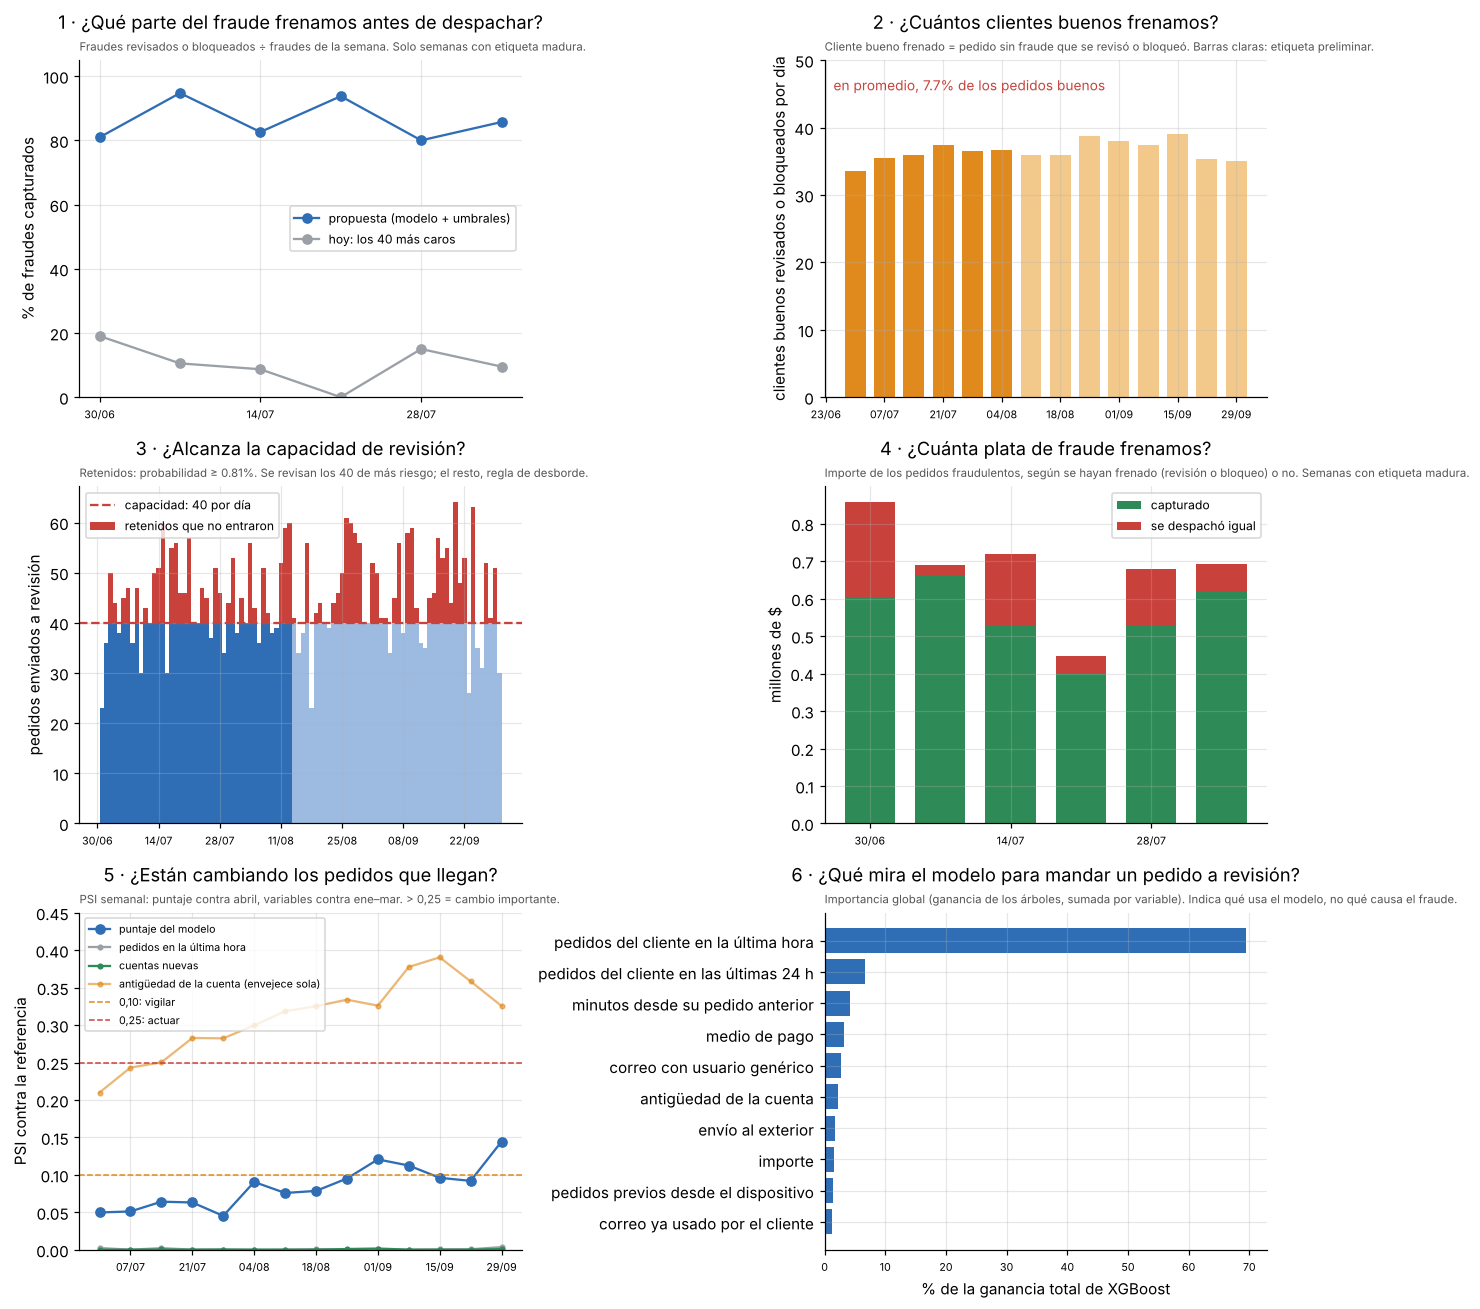

In [39]:
import os
os.makedirs("img", exist_ok=True)
NOMBRES = {"log_importe": "importe", "cantidad_items": "cantidad de ítems", "cuotas": "cuotas", "hora": "hora del pedido", "madrugada": "compra de madrugada",
           "fin_de_semana": "fin de semana", "envio_exterior": "envío al exterior", "antig_cuenta_dias": "antigüedad de la cuenta", "telefono_verificado": "teléfono verificado",
           "disp_faltante": "sin dato de dispositivo", "disp_antig_dias": "antigüedad del dispositivo", "disp_pedidos_previos": "pedidos previos desde el dispositivo",
           "email_generico": "correo con usuario genérico", "email_corporativo": "correo corporativo", "email_ya_usado": "correo ya usado por el cliente",
           "cli_pedidos_previos": "pedidos previos del cliente", "min_desde_anterior": "minutos desde su pedido anterior", "cli_pedidos_1h": "pedidos del cliente en la última hora",
           "cli_pedidos_24h": "pedidos del cliente en las últimas 24 h", "metodo_pago": "medio de pago", "tipo": "tipo de dispositivo", "provincia": "provincia"}

def variable_original(nombre_transformado):
    n = nombre_transformado.split("__", 1)[1].replace("missingindicator_", "")
    return n if n in NOMBRES else next(c for c in CAT if n.startswith(c + "_"))

imp_xgb = pd.Series(modelo_sim.named_steps["modelo"].feature_importances_, index=modelo_sim.named_steps["prep"].get_feature_names_out())
importancia = imp_xgb.groupby(imp_xgb.index.map(variable_original)).sum().sort_values(ascending=False)
importancia = importancia / importancia.sum()

sem = diario.groupby("semana").agg(**{c: (c, "sum") for c in ["pedidos", "a_revisar", "bloqueados", "fraudes", "fraudes_capturados", "fraudes_capturados_hoy", "buenos_frenados", "monto_fraude", "monto_fraude_capturado"]},
                                   dias=("dia", "nunique"), etiqueta=("etiqueta", "last")).reset_index()
sem_mad = sem[sem.etiqueta == "madura"]

def definicion_(ax, texto): ax.text(0, 1.02, texto, transform=ax.transAxes, fontsize=7.5, color="#555", va="bottom")

fig, axs = plt.subplots(3, 2, figsize=(13, 12)); axs = axs.ravel()
ax = axs[0]
ax.plot(sem_mad.semana, sem_mad.fraudes_capturados / sem_mad.fraudes * 100, marker="o", color=AZUL, label="propuesta (modelo + umbrales)")
ax.plot(sem_mad.semana, sem_mad.fraudes_capturados_hoy / sem_mad.fraudes * 100, marker="o", color=GRIS, label="hoy: los 40 más caros")
ax.set(title="1 · ¿Qué parte del fraude frenamos antes de despachar?\n", ylabel="% de fraudes capturados", ylim=(0, 105)); ax.legend(fontsize=8)
definicion_(ax, "Fraudes revisados o bloqueados ÷ fraudes de la semana. Solo semanas con etiqueta madura.")
ax = axs[1]
ax.bar(sem.semana, sem.buenos_frenados / sem.dias, width=5, color=[NARANJA if e == "madura" else "#f3c98b" for e in sem.etiqueta])
friccion = sem.buenos_frenados.sum() / (sem.pedidos - sem.fraudes).sum()
ax.text(0.02, 0.95, f"en promedio, {friccion:.1%} de los pedidos buenos", transform=ax.transAxes, fontsize=9, color=ROJO, va="top")
ax.set(title="2 · ¿Cuántos clientes buenos frenamos?\n", ylabel="clientes buenos revisados o bloqueados por día", ylim=(0, 50))
definicion_(ax, "Cliente bueno frenado = pedido sin fraude que se revisó o bloqueó. Barras claras: etiqueta preliminar.")
ax = axs[2]
ax.bar(diario.dia, diario.a_revisar, color=[AZUL if e == "madura" else "#9dbbe0" for e in diario.etiqueta], width=1)
ax.axhline(CAPACIDAD, color=ROJO, ls="--", label=f"capacidad: {CAPACIDAD} por día"); ax.bar(diario.dia, diario.desbordados, bottom=diario.a_revisar, color=ROJO, width=1, label="retenidos que no entraron")
ax.set(title="3 · ¿Alcanza la capacidad de revisión?\n", ylabel="pedidos enviados a revisión"); ax.legend(fontsize=8)
definicion_(ax, f"Retenidos: probabilidad ≥ {T_REVISION:.2%}. Se revisan los 40 de más riesgo; el resto, regla de desborde.")
ax = axs[3]
ax.bar(sem_mad.semana, sem_mad.monto_fraude_capturado / 1e6, width=5, color=VERDE, label="capturado")
ax.bar(sem_mad.semana, (sem_mad.monto_fraude - sem_mad.monto_fraude_capturado) / 1e6, bottom=sem_mad.monto_fraude_capturado / 1e6, width=5, color=ROJO, label="se despachó igual")
ax.set(title="4 · ¿Cuánta plata de fraude frenamos?\n", ylabel="millones de $"); ax.legend(fontsize=8)
definicion_(ax, "Importe de los pedidos fraudulentos, según se hayan frenado (revisión o bloqueo) o no. Semanas con etiqueta madura.")
ax = axs[4]
ax.plot(deriva_semanal.semana, deriva_semanal.psi_puntaje, marker="o", color=AZUL, label="puntaje del modelo")
ax.plot(deriva_semanal.semana, deriva_semanal.psi_cli_pedidos_1h, marker=".", color=GRIS, label="pedidos en la última hora")
ax.plot(deriva_semanal.semana, deriva_semanal.psi_cuenta_nueva_7d, marker=".", color=VERDE, label="cuentas nuevas")
ax.plot(deriva_semanal.semana, deriva_semanal.psi_antig_cuenta_dias, marker=".", color=NARANJA, alpha=0.6, label="antigüedad de la cuenta (envejece sola)")
ax.axhline(0.1, color=NARANJA, ls="--", lw=1, label="0,10: vigilar"); ax.axhline(0.25, color=ROJO, ls="--", lw=1, label="0,25: actuar")
ax.set(title="5 · ¿Están cambiando los pedidos que llegan?\n", ylabel="PSI contra la referencia", ylim=(0, 0.45)); ax.legend(fontsize=7, loc="upper left", ncol=1)
definicion_(ax, "PSI semanal: puntaje contra abril, variables contra ene–mar. > 0,25 = cambio importante.")
ax = axs[5]
top = importancia.head(10).iloc[::-1]; ax.barh([NOMBRES[i] for i in top.index], top.values * 100, color=AZUL)
ax.set(title="6 · ¿Qué mira el modelo para mandar un pedido a revisión?\n", xlabel="% de la ganancia total de XGBoost")
definicion_(ax, "Importancia global (ganancia de los árboles, sumada por variable). Indica qué usa el modelo, no qué causa el fraude.")
import matplotlib.dates as mdates
for i, a in enumerate(axs):
    a.tick_params(axis="x", labelsize=7)
    if i < 5: a.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2)); a.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.tight_layout(); fig.savefig("img/tablero_vidriera.png", dpi=130, bbox_inches="tight")
renderer = fig.canvas.get_renderer()
for i, a in enumerate(axs):                      # cada gráfico también por separado, para la presentación
    from matplotlib.transforms import Bbox
    tb, ventana = a.get_tightbbox(renderer), a.get_window_extent(renderer)
    caja = Bbox.from_extents(tb.x0 - 8, tb.y0 - 8, min(tb.x1, ventana.x1 + 12), tb.y1 + 8).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(f"img/grafico_{i + 1}.png", dpi=150, bbox_inches=caja)
plt.show()

**Lectura del tablero:** (1) la propuesta captura de forma estable la mayor parte del fraude semana a semana, frente a una fracción chica con la regla de hoy; (2) el costo es demorar a unos 35 clientes buenos por día (~7 % de los pedidos buenos), sin bloquear a casi nadie; (3) muchos días hay algo más de 40 retenidos: los de menor riesgo se liberan por la regla de desborde, y es el gráfico que diría si hace falta más capacidad; (5) el puntaje del modelo **se va corriendo de a poco y cruza 0,10 («vigilar») a principios de septiembre**: es la señal para adelantar el reentrenamiento, que hacemos en la sección 7. La **antigüedad de la cuenta se mueve sola** porque las cuentas envejecen con el calendario (un PSI alto esperable, que no indica fraude): por eso se vigila la proporción de cuentas nuevas, que está quieta. Es también una razón para reentrenar seguido, porque el modelo usa la antigüedad.

Exportamos las tablas para Superset. `pedidos_puntuados` es la base del tablero (cada pedido con su probabilidad, su decisión y sus tres motivos principales); las otras son agregados listos para graficar.

In [40]:
import xgboost as xgb
def motivos(modelo, d, n=3, minimo=0.1):
    """Las n variables que más empujaron el riesgo hacia arriba en cada pedido (contribuciones de XGBoost, en log-odds; se omiten las menores a `minimo`)."""
    X = modelo.named_steps["prep"].transform(d[VARIABLES_MODELO])
    contrib = modelo.named_steps["modelo"].get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]
    c = pd.DataFrame(contrib, columns=modelo.named_steps["prep"].get_feature_names_out(), index=d.index)
    c = c.T.groupby(c.columns.map(variable_original)).sum().T
    orden = np.argsort(-c.values, axis=1)[:, :n]
    return pd.DataFrame([[NOMBRES[c.columns[j]] if c.values[i, j] >= minimo else "" for j in fila] for i, fila in enumerate(orden)], index=d.index, columns=[f"motivo_{k+1}" for k in range(n)])

operacion = operacion.join(motivos(modelo_sim, operacion))
pedidos_puntuados = operacion[["id_pedido", "fecha_hora", "dia", "importe", "metodo_pago", "cuotas", "pais_envio", "p", "decision", "decision_hoy", "desbordado",
                               "fraude", "etiqueta", "motivo_1", "motivo_2", "motivo_3"]].rename(columns={"p": "probabilidad"})
pedidos_puntuados["fraude"] = pedidos_puntuados.fraude.where(operacion.madura)       # vacío si la etiqueta no maduró
metricas_modelos = pd.concat([res_prueba.assign(tramo="prueba"), red_vs[red_vs.modelo.str.startswith("red")]], ignore_index=True)
metricas_modelos = metricas_modelos[["modelo", "tramo", "PR-AUC", "ROC-AUC", "recall en cola 40", "precisión en cola 40", "monto capturado", "buenos revisados por día"]]
metricas_modelos.columns = ["modelo", "tramo", "pr_auc", "roc_auc", "recall_cola_40", "precision_cola_40", "monto_capturado", "buenos_revisados_dia"]
politicas_costo = tabla_politicas.rename(columns=lambda c: re.sub(r"[^a-z0-9]+", "_", c.lower().replace("($)", "")).strip("_"))
exportar_superset(pedidos_puntuados=pedidos_puntuados.assign(fecha_hora=pedidos_puntuados.fecha_hora.astype(str), dia=pedidos_puntuados.dia.dt.date.astype(str)),
                  resumen_diario=diario.assign(dia=diario.dia.dt.date.astype(str), semana=diario.semana.dt.date.astype(str)),
                  deriva_semanal=deriva_semanal.assign(semana=deriva_semanal.semana.dt.date.astype(str)),
                  metricas_modelos=metricas_modelos, politicas_costo=politicas_costo,
                  importancia_global=importancia.rename_axis("variable").reset_index(name="importancia").assign(variable=lambda t: t.variable.map(NOMBRES)),
                  bitacora_calidad=bitacora_calidad.astype(str))

Listo: superset/07_Vidriera.db y un CSV por tabla. Conectá Superset a ese archivo.


'superset'

**Cómo armar el tablero en Superset** (la guía completa está en `superset/README.md`): conectar la base `superset/07_Vidriera.db` (SQLite), crear un dataset por tabla y estos seis gráficos:

| # | Pregunta | Dataset | Gráfico | Métrica |
| --- | --- | --- | --- | --- |
| 1 | ¿Qué parte del fraude frenamos? | `resumen_diario` (filtro `etiqueta = 'madura'`) | Línea por `semana` | `SUM(fraudes_capturados)/SUM(fraudes)` y `SUM(fraudes_capturados_hoy)/SUM(fraudes)` |
| 2 | ¿Cuántos clientes buenos frenamos? | `resumen_diario` | Barras por `semana` | `SUM(buenos_frenados)/COUNT(dia)` |
| 3 | ¿Alcanza la capacidad? | `resumen_diario` | Barras por `dia` con línea de 40 | `SUM(a_revisar)`, `SUM(desbordados)` |
| 4 | ¿Cuánta plata frenamos? | `resumen_diario` (madura) | Barras apiladas por `semana` | `SUM(monto_fraude_capturado)`, `SUM(monto_fraude) - SUM(monto_fraude_capturado)` |
| 5 | ¿Cambian los pedidos? | `deriva_semanal` | Línea por `semana` | `psi_puntaje`, `psi_cli_pedidos_1h` |
| 6 | ¿Por qué entra un pedido a la cola? | `pedidos_puntuados` (filtro `decision = 'revisar'`) | Tabla | `id_pedido`, `probabilidad`, `motivo_1..3`, ordenada por probabilidad |

## 7 · Producción

**Qué tenés que resolver en tu caso:** Contrato de entrada, tiempo de respuesta en milisegundos, dos umbrales y deriva, porque quienes defraudan se adaptan.

Definí el contrato de entrada (campos, tipos y rangos), la versión, una prueba de humo y las señales de monitoreo con umbral, acción y responsable.

### 7.1 Reentrenamiento y versión

El modelo de la simulación (`1.0.0`) se entrenó con enero a marzo. Hoy, 15/10/2025, las etiquetas maduras llegan hasta el 13/8, así que **reentrenamos con la misma receta** y lo publicamos como `1.1.0`:

* entrenamiento: 01/01 al 13/07 · calibración: 14/07 al 13/08 (el último mes maduro);
* mismos hiperparámetros, mismas variables, mismos umbrales de costo; el umbral de revisión se recalcula para que la cola siga en ~36 por día.

In [41]:
import hashlib, json, joblib, yaml, sklearn
os.makedirs("modelo", exist_ok=True)
VERSION = "1.1.0"
ent_prod = maduros[maduros.fecha_hora < "2025-07-14"]; cal_prod = maduros[maduros.fecha_hora >= "2025-07-14"]
modelo_prod = Pipeline([("prep", preprocesador(VARIABLES_MODELO)), ("modelo", XGBClassifier(**candidatos[MODELO_ELEGIDO].get_params()))]).fit(ent_prod[VARIABLES_MODELO], ent_prod.fraude)
platt_prod = LogisticRegression(C=1e6).fit(logit(modelo_prod.predict_proba(cal_prod[VARIABLES_MODELO])[:, 1]).reshape(-1, 1), cal_prod.fraude)
p_cal_prod = probabilidad(modelo_prod, platt_prod, cal_prod)
UMBRALES = {"revision": umbral_revision(cal_prod, p_cal_prod), "bloqueo": T_BLOQUEO, "desborde": T_DESBORDE, "capacidad_diaria": CAPACIDAD}
huella_datos = hashlib.sha256(pd.util.hash_pandas_object(ent_prod[["id_pedido", "fraude"]], index=False).values.tobytes()).hexdigest()[:16]
metadatos = {
    "nombre": "vidriera-fraude-precontracargo", "version": VERSION, "creado": "2025-10-15", "algoritmo": MODELO_ELEGIDO,
    "hiperparametros": {k: v for k, v in candidatos[MODELO_ELEGIDO].get_params().items() if k in ("n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "min_child_weight", "reg_lambda", "scale_pos_weight")},
    "datos": {"entrenamiento": [str(ent_prod.fecha_hora.min().date()), str(ent_prod.fecha_hora.max().date())], "calibracion": [str(cal_prod.fecha_hora.min().date()), str(cal_prod.fecha_hora.max().date())],
              "pedidos": len(ent_prod), "fraudes": int(ent_prod.fraude.sum()), "huella_sha256": huella_datos, "maduracion_dias": MADURACION},
    "variables": VARIABLES_MODELO, "umbrales": UMBRALES, "costos_supuestos": COSTOS,
    "metricas_version_1_0_0_en_prueba": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in evaluar(pru, pru.p, nombre=MODELO_ELEGIDO).items()},
    "librerias": {"python-sklearn": sklearn.__version__, "xgboost": xgb.__version__, "pandas": pd.__version__},
    "responsable": "Equipo 7 · Ciencia de datos (dueño del modelo) · Prevención de fraude (dueño de la decisión)",
}
joblib.dump({"pipeline": modelo_prod, "calibrador": platt_prod, "metadatos": metadatos}, f"modelo/vidriera_fraude_{VERSION}.joblib")
with open(f"modelo/vidriera_fraude_{VERSION}.json", "w", encoding="utf-8") as f: json.dump(metadatos, f, ensure_ascii=False, indent=2, default=str)
print(json.dumps({k: metadatos[k] for k in ("version", "algoritmo", "datos", "umbrales")}, ensure_ascii=False, indent=2, default=str))

{
  "version": "1.1.0",
  "algoritmo": "xgboost (parsimonioso, peso 10, prof. 3)",
  "datos": {
    "entrenamiento": [
      "2025-01-01",
      "2025-07-13"
    ],
    "calibracion": [
      "2025-07-14",
      "2025-08-13"
    ],
    "pedidos": 93385,
    "fraudes": 630,
    "huella_sha256": "70f6244bc7b2da17",
    "maduracion_dias": 62
  },
  "umbrales": {
    "revision": 0.00942865801942623,
    "bloqueo": 0.4159629567492517,
    "desborde": 0.09652135576627657,
    "capacidad_diaria": 40
  }
}


### 7.2 Contrato de entrada

El servicio de puntaje recibe **un pedido por vez**, antes del despacho. Pide solo las variables que usa el modelo elegido (más el importe y la hora, de los que deriva el logaritmo del importe y la marca de madrugada). Las variables de historia (pedidos en la última hora, antigüedad del dispositivo…) las calcula el sistema de pedidos con la misma función `construir_variables` y viajan en la solicitud. El contrato fija **campos, tipos, rangos y valores permitidos**, y rechaza campos de más (por ejemplo, `fraude` o `fecha_contracargo`: si llegaran, sería una fuga).

In [42]:
def rango(col, margen=0.0):
    return [float(maduros[col].min()), float(maduros[col].max() * (1 + margen))]

CONTRATO = {
    "version_contrato": "1.0", "modelo": f"vidriera-fraude-precontracargo {VERSION}", "campos_extra": "rechazar",
    "campos": {
        "id_pedido": {"tipo": "entero", "requerido": True, "min": 1},
        "importe": {"tipo": "decimal", "requerido": True, "min": 1, "max": 5_000_000, "unidad": "pesos, con punto decimal"},
        "cantidad_items": {"tipo": "entero", "requerido": True, "min": 1, "max": 50},
        "cuotas": {"tipo": "entero", "requerido": True, "valores": [1, 3, 6, 12]},
        "metodo_pago": {"tipo": "texto", "requerido": True, "valores": sorted(maduros.metodo_pago.unique().tolist())},
        "hora": {"tipo": "entero", "requerido": True, "min": 0, "max": 23, "unidad": "hora local de Argentina"},
        "fin_de_semana": {"tipo": "entero", "requerido": True, "valores": [0, 1]},
        "envio_exterior": {"tipo": "entero", "requerido": True, "valores": [0, 1]},
        "antig_cuenta_dias": {"tipo": "decimal", "requerido": True, "min": 0, "max": 36500},
        "telefono_verificado": {"tipo": "entero", "requerido": True, "valores": [0, 1]},
        "disp_faltante": {"tipo": "entero", "requerido": True, "valores": [0, 1]},
        "disp_antig_dias": {"tipo": "decimal", "requerido": False, "min": 0, "max": 36500, "nulo_si": "disp_faltante = 1"},
        "disp_pedidos_previos": {"tipo": "decimal", "requerido": False, "min": 0, "max": 100000, "nulo_si": "disp_faltante = 1"},
        "email_generico": {"tipo": "entero", "requerido": True, "valores": [0, 1]},
        "email_corporativo": {"tipo": "entero", "requerido": True, "valores": [0, 1]},
        "email_ya_usado": {"tipo": "entero", "requerido": True, "valores": [0, 1]},
        "cli_pedidos_previos": {"tipo": "entero", "requerido": True, "min": 0, "max": 100000},
        "min_desde_anterior": {"tipo": "decimal", "requerido": True, "min": 0, "max": 100000, "nota": "100000 si es su primer pedido"},
        "cli_pedidos_1h": {"tipo": "entero", "requerido": True, "min": 0, "max": 500},
        "cli_pedidos_24h": {"tipo": "entero", "requerido": True, "min": 0, "max": 5000},
        "tipo": {"tipo": "texto", "requerido": False, "valores": sorted(maduros.tipo.dropna().unique().tolist()), "nulo_si": "disp_faltante = 1"},
        "provincia": {"tipo": "texto", "requerido": True, "valores": sorted(maduros.provincia.unique().tolist())},
    },
    "respuesta": {"200": "id_pedido, probabilidad, decision (aprobar | revisar | bloquear), motivos, version, ms",
                  "422": "lista de errores de validación; el pedido va a revisión manual por defecto (falla segura)"},
    "tiempo_de_respuesta": "p95 < 50 ms por pedido",
}
necesarios = {"id_pedido", "importe", "hora"} | set(VARIABLES_MODELO)          # importe y hora: el servicio deriva log_importe y madrugada
CONTRATO["campos"] = {k: v for k, v in CONTRATO["campos"].items() if k in necesarios}
assert set(VARIABLES_MODELO) - {"log_importe", "madrugada"} <= set(CONTRATO["campos"]), "el contrato no cubre todas las variables del modelo"
with open("modelo/contrato_entrada.yaml", "w", encoding="utf-8") as f: yaml.safe_dump(CONTRATO, f, allow_unicode=True, sort_keys=False)
print(open("modelo/contrato_entrada.yaml", encoding="utf-8").read()[:1400], "…")

version_contrato: '1.0'
modelo: vidriera-fraude-precontracargo 1.1.0
campos_extra: rechazar
campos:
  id_pedido:
    tipo: entero
    requerido: true
    min: 1
  importe:
    tipo: decimal
    requerido: true
    min: 1
    max: 5000000
    unidad: pesos, con punto decimal
  cantidad_items:
    tipo: entero
    requerido: true
    min: 1
    max: 50
  cuotas:
    tipo: entero
    requerido: true
    valores:
    - 1
    - 3
    - 6
    - 12
  metodo_pago:
    tipo: texto
    requerido: true
    valores:
    - billetera
    - credito
    - debito
  hora:
    tipo: entero
    requerido: true
    min: 0
    max: 23
    unidad: hora local de Argentina
  envio_exterior:
    tipo: entero
    requerido: true
    valores:
    - 0
    - 1
  antig_cuenta_dias:
    tipo: decimal
    requerido: true
    min: 0
    max: 36500
  disp_faltante:
    tipo: entero
    requerido: true
    valores:
    - 0
    - 1
  disp_antig_dias:
    tipo: decimal
    requerido: false
    min: 0
    max: 36500
    nul

### 7.3 El servicio de puntaje

Una función `responder(pedido)` que hace lo mismo que haría la API: valida contra el contrato, puntúa, aplica los dos umbrales y devuelve los motivos para el analista. Si el pedido no cumple el contrato responde **422** y el pedido va a **revisión manual**: ante la duda, no se despacha sin mirar.

In [43]:
CAMPOS_MODELO = [c for c in CONTRATO["campos"] if c != "id_pedido"]

def validar(pedido, contrato=CONTRATO):
    errores = []
    extra = set(pedido) - set(contrato["campos"])
    if extra: errores.append(f"campos no permitidos: {sorted(extra)}")
    for campo, regla in contrato["campos"].items():
        v = pedido.get(campo)
        if v is None or (isinstance(v, float) and math.isnan(v)):
            if regla["requerido"]: errores.append(f"{campo}: falta")
            continue
        if regla["tipo"] in ("entero", "decimal"):
            if isinstance(v, bool) or not isinstance(v, (int, float, np.integer, np.floating)): errores.append(f"{campo}: debe ser numérico"); continue
            if regla["tipo"] == "entero" and float(v) != int(v): errores.append(f"{campo}: debe ser entero")
        elif not isinstance(v, str): errores.append(f"{campo}: debe ser texto"); continue
        if "valores" in regla and v not in regla["valores"]: errores.append(f"{campo}: valor {v!r} no permitido")
        if "min" in regla and v < regla["min"]: errores.append(f"{campo}: {v} menor que {regla['min']}")
        if "max" in regla and v > regla["max"]: errores.append(f"{campo}: {v} mayor que {regla['max']}")
    return errores

class ServicioFraude:
    def __init__(self, ruta):
        art = joblib.load(ruta); self.pipe, self.cal, self.meta = art["pipeline"], art["calibrador"], art["metadatos"]; self.u = self.meta["umbrales"]
    def responder(self, pedido):
        t0 = time.perf_counter(); errores = validar(pedido)
        if errores:
            return {"status": 422, "id_pedido": pedido.get("id_pedido"), "decision": "revisar", "errores": errores, "version": self.meta["version"], "ms": (time.perf_counter() - t0) * 1000}
        x = pd.DataFrame([{**pedido, "log_importe": np.log(pedido["importe"]), "madrugada": int(pedido["hora"] < 6)}])
        for c in ("disp_antig_dias", "disp_pedidos_previos"):
            if c in x: x[c] = x[c].astype(float)
        p = float(self.cal.predict_proba(logit(self.pipe.predict_proba(x[VARIABLES_MODELO])[:, 1]).reshape(-1, 1))[0, 1])
        decision = "bloquear" if p >= self.u["bloqueo"] else "revisar" if p >= self.u["revision"] else "aprobar"
        return {"status": 200, "id_pedido": pedido["id_pedido"], "probabilidad": round(p, 4), "decision": decision,
                "motivos": [m for m in motivos(self.pipe, x).iloc[0].tolist() if m] if decision != "aprobar" else [],
                "version": self.meta["version"], "ms": round((time.perf_counter() - t0) * 1000, 2)}

def a_pedido(fila):
    """Convierte una fila de la tabla en la solicitud que mandaría el sistema de pedidos."""
    r = {"id_pedido": int(fila.id_pedido), "importe": float(fila.importe)}
    for c in CAMPOS_MODELO:
        if c == "importe": continue
        v = fila[c]
        r[c] = None if pd.isna(v) else (v if isinstance(v, str) else (int(v) if CONTRATO["campos"][c]["tipo"] == "entero" else float(v)))
    return r

servicio = ServicioFraude(f"modelo/vidriera_fraude_{VERSION}.joblib")
ejemplo = operacion.sort_values("p", ascending=False).iloc[0]
servicio.responder(a_pedido(ejemplo))

{'status': 200,
 'id_pedido': 122298,
 'probabilidad': 0.2833,
 'decision': 'revisar',
 'motivos': ['pedidos del cliente en la última hora',
  'minutos desde su pedido anterior',
  'antigüedad de la cuenta'],
 'version': '1.1.0',
 'ms': 14.89}

### 7.4 Prueba de humo

Se corre cada vez que se publica una versión. Si falla una sola, no se publica.

In [44]:
def prueba_de_humo(ruta):
    s = ServicioFraude(ruta); resultados = []
    def chequear(nombre, ok): resultados.append((nombre, bool(ok)))
    chequear("la versión del artefacto es la esperada", s.meta["version"] == VERSION)
    riesgoso = a_pedido(operacion.sort_values("p", ascending=False).iloc[0]); normal = a_pedido(operacion[operacion.p < 0.001].iloc[0])
    r1, r2 = s.responder(riesgoso), s.responder(normal)
    chequear("el pedido de mayor riesgo no se aprueba", r1["status"] == 200 and r1["decision"] != "aprobar")
    chequear("un pedido típico se aprueba", r2["status"] == 200 and r2["decision"] == "aprobar")
    chequear("la probabilidad está entre 0 y 1", 0 <= r1["probabilidad"] <= 1 and 0 <= r2["probabilidad"] <= 1)
    chequear("importe negativo → 422", s.responder({**normal, "importe": -10.0})["status"] == 422)
    chequear("medio de pago desconocido → 422", s.responder({**normal, "metodo_pago": "cripto"})["status"] == 422)
    chequear("falta un campo requerido → 422", s.responder({k: v for k, v in normal.items() if k != "cli_pedidos_1h"})["status"] == 422)
    chequear("campo de más (fuga: 'fraude') → 422", s.responder({**normal, "fraude": 1})["status"] == 422)
    chequear("un 422 manda el pedido a revisión (falla segura)", s.responder({**normal, "importe": -10.0})["decision"] == "revisar")
    muestra = cal_prod.sample(500, random_state=SEMILLA)
    lote = probabilidad(modelo_prod, platt_prod, muestra); uno_a_uno = [s.responder(a_pedido(f))["probabilidad"] for _, f in muestra.head(50).iterrows()]
    chequear("el servicio reproduce las probabilidades del notebook", np.allclose(np.round(lote[:50], 4), uno_a_uno, atol=1e-4))
    t = [s.responder(a_pedido(f))["ms"] for _, f in muestra.iterrows()]
    p50, p95, p99 = np.percentile(t, [50, 95, 99])
    chequear(f"tiempo de respuesta p95 < 50 ms (p50 {p50:.1f} · p95 {p95:.1f} · p99 {p99:.1f} ms)", p95 < 50)
    for nombre, ok in resultados: print(("✅" if ok else "❌"), nombre)
    assert all(ok for _, ok in resultados), "la prueba de humo falló: no publicar"
    return {"p50_ms": p50, "p95_ms": p95, "p99_ms": p99}

LATENCIA = prueba_de_humo(f"modelo/vidriera_fraude_{VERSION}.joblib")

✅ la versión del artefacto es la esperada
✅ el pedido de mayor riesgo no se aprueba
✅ un pedido típico se aprueba
✅ la probabilidad está entre 0 y 1
✅ importe negativo → 422
✅ medio de pago desconocido → 422
✅ falta un campo requerido → 422
✅ campo de más (fuga: 'fraude') → 422
✅ un 422 manda el pedido a revisión (falla segura)
✅ el servicio reproduce las probabilidades del notebook
✅ tiempo de respuesta p95 < 50 ms (p50 4.7 · p95 9.5 · p99 13.8 ms)


El tiempo incluye validar, armar la fila, preprocesar, puntuar y calcular los motivos. Con XGBoost de 300 árboles poco profundos queda muy por debajo de los 50 ms, aun en una máquina modesta.

### 7.5 Deriva: quienes defraudan se adaptan

Hay dos tipos de cambio y se vigilan distinto:

* **Cambian los pedidos que llegan** (deriva de datos): se ve enseguida, sin esperar etiquetas, con el PSI del puntaje y de las variables clave (gráfico 5 del tablero).
* **Cambia la forma de defraudar** (deriva de concepto): los pedidos se ven iguales pero el fraude aparece en otro lado. Solo se ve con etiquetas, y la etiqueta tarda 62 días. Por eso usamos además una **señal temprana**: el resultado de las revisiones del analista (si confirma fraude o no) se conoce en horas.

**Lo que ya muestra el tablero (gráfico 5):** el puntaje del modelo 1.0.0 se corre de a poco y cruza 0,10 a principios de septiembre. Ninguna de las señales de fraude conocidas se movió (ráfagas, cuentas nuevas, correos genéricos): el corrimiento viene de variables que cambian con el calendario, como la antigüedad de las cuentas. Es la alarma amarilla del plan y la respuesta es la de esta sección: reentrenar con los datos maduros más recientes (1.1.0).

Un ejemplo de deriva de concepto que habría que mirar: la tasa de fraude de un segmento concreto antes y después de una fecha. Lo calculamos para «billetera en 1 cuota», un medio rápido y sin financiación, alrededor del 15/7.

In [45]:
seg = maduros.assign(segmento=np.where((maduros.metodo_pago == "billetera") & (maduros.cuotas == 1), "billetera en 1 cuota", "resto"),
                     periodo=np.where(maduros.fecha_hora >= "2025-07-15", "desde el 15/7", "hasta el 14/7"))
t_seg = seg.groupby(["segmento", "periodo"]).agg(pedidos=("fraude", "size"), fraudes=("fraude", "sum"))
t_seg["tasa"] = t_seg.fraudes / t_seg.pedidos
t_seg["IC 95 %"] = ["[{:.2%} ; {:.2%}]".format(*wilson(r.fraudes, r.pedidos)) for r in t_seg.itertuples()]
t_seg.style.format({"tasa": "{:.2%}"})

In [46]:
psi_reciente = deriva_semanal[deriva_semanal.semana >= "2025-08-14"].drop(columns=["semana", "pedidos", "% billetera en 1 cuota"]).max()
print("PSI máximo semanal desde el 14/8 (etiquetas aún sin madurar), por señal:")
print(psi_reciente.round(3).to_string())

PSI máximo semanal desde el 14/8 (etiquetas aún sin madurar), por señal:
psi_puntaje              0.144
psi_log_importe          0.011
psi_antig_cuenta_dias    0.390
psi_cuenta_nueva_7d      0.002
psi_cli_pedidos_1h       0.004
psi_email_generico       0.001
psi_envio_exterior       0.001
psi_madrugada            0.000


Con un mes de datos post-15/7 y pocos fraudes por segmento, los intervalos son anchos: **no se puede afirmar ni descartar** un cambio en ese segmento. Es justamente el problema de la deriva de concepto con etiquetas demoradas: cuando la evidencia es concluyente, ya pasaron meses. El plan de monitoreo responde a eso con señales rápidas (revisiones del analista) y lentas (contracargos maduros).

### 7.6 Plan de monitoreo

In [47]:
plan_monitoreo = pd.DataFrame([
    ("Pedidos rechazados por el contrato (422)", "% diario de solicitudes con 422", "diaria", "> 0,5 % en un día", "Revisar el sistema de pedidos que arma las variables; los 422 ya van a revisión manual", "Ingeniería de datos"),
    ("Tiempo de respuesta", "p95 de ms por pedido", "continua", "p95 > 50 ms durante 15 min", "Escalar el servicio; si sigue, pasar a la regla de puntos (respaldo)", "Ingeniería / plataforma"),
    ("Volumen de la cola", "pedidos enviados a revisión por día", "diaria", "> 40 durante 3 días seguidos, o < 20", "Revisar umbral de revisión; si es un ataque, activar la regla de desborde", "Prevención de fraude"),
    ("Deriva del puntaje", "PSI semanal contra la calibración", "semanal", "> 0,10 vigilar · > 0,25 actuar", "Analizar qué variable se movió; adelantar el reentrenamiento", "Ciencia de datos"),
    ("Precisión de la cola (señal temprana)", "% de revisados que el analista confirma como fraude", "semanal", "< 3 % (hoy ~6 %)", "Muestrear casos con el analista; buscar nuevos patrones de fraude", "Prevención de fraude + Ciencia de datos"),
    ("Fraude capturado (señal madura)", "recall de bloqueo + revisión con etiquetas de 62 días", "mensual", "< 75 % o por debajo de la regla de puntos", "Reentrenar; si no mejora, volver a la regla y rediseñar variables", "Ciencia de datos"),
    ("Fraude no capturado en $", "monto de contracargos «no reconoce» de pedidos aprobados", "mensual", "> 30 % arriba del promedio de 3 meses", "Informe a dirección comercial; revisar costos y capacidad", "Finanzas"),
    ("Fricción a clientes buenos", "clientes buenos revisados o bloqueados / pedidos buenos", "semanal", "> 10 %", "Subir el umbral de revisión; revisar abandono de bloqueados", "Prevención de fraude"),
    ("Calibración", "probabilidad media vs tasa observada madura", "mensual", "fuera del IC 95 % en 2 meses seguidos", "Recalibrar con el último mes maduro", "Ciencia de datos"),
], columns=["señal", "cómo se mide", "frecuencia", "umbral", "acción", "responsable"])
plan_monitoreo.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,señal,cómo se mide,frecuencia,umbral,acción,responsable
0,Pedidos rechazados por el contrato (422),% diario de solicitudes con 422,diaria,"> 0,5 % en un día",Revisar el sistema de pedidos que arma las variables; los 422 ya van a revisión manual,Ingeniería de datos
1,Tiempo de respuesta,p95 de ms por pedido,continua,p95 > 50 ms durante 15 min,"Escalar el servicio; si sigue, pasar a la regla de puntos (respaldo)",Ingeniería / plataforma
2,Volumen de la cola,pedidos enviados a revisión por día,diaria,"> 40 durante 3 días seguidos, o < 20","Revisar umbral de revisión; si es un ataque, activar la regla de desborde",Prevención de fraude
3,Deriva del puntaje,PSI semanal contra la calibración,semanal,"> 0,10 vigilar · > 0,25 actuar",Analizar qué variable se movió; adelantar el reentrenamiento,Ciencia de datos
4,Precisión de la cola (señal temprana),% de revisados que el analista confirma como fraude,semanal,< 3 % (hoy ~6 %),Muestrear casos con el analista; buscar nuevos patrones de fraude,Prevención de fraude + Ciencia de datos
5,Fraude capturado (señal madura),recall de bloqueo + revisión con etiquetas de 62 días,mensual,< 75 % o por debajo de la regla de puntos,"Reentrenar; si no mejora, volver a la regla y rediseñar variables",Ciencia de datos
6,Fraude no capturado en $,monto de contracargos «no reconoce» de pedidos aprobados,mensual,> 30 % arriba del promedio de 3 meses,Informe a dirección comercial; revisar costos y capacidad,Finanzas
7,Fricción a clientes buenos,clientes buenos revisados o bloqueados / pedidos buenos,semanal,> 10 %,Subir el umbral de revisión; revisar abandono de bloqueados,Prevención de fraude
8,Calibración,probabilidad media vs tasa observada madura,mensual,fuera del IC 95 % en 2 meses seguidos,Recalibrar con el último mes maduro,Ciencia de datos


**Reentrenamiento:** mensual, siempre con la brecha de 62 días (entrenar con los pedidos que ya maduraron) y publicando una versión nueva solo si supera a la vigente **y a la regla de puntos** en el último mes maduro y pasa la prueba de humo. La regla de puntos queda siempre disponible como respaldo.

## 8 · Negocio

**Qué tenés que resolver en tu caso:** El costo de un contracargo frente al de frenar a un cliente bueno; explicación para el analista que revisa.

Decisión, costos, explicación global y local, y una recomendación proporcional a la evidencia.

### 8.1 El costo de cada error

Un contracargo cuesta **el importe completo más la comisión** (la mercadería ya salió). Frenar a un cliente bueno cuesta **una fracción del margen**, y solo si abandona. Con los supuestos de abajo, **un fraude que pasa cuesta lo mismo que bloquear a unos 9 clientes buenos**, y muchísimo más que revisar a uno (que no cuesta nada si hay capacidad). Como en el tramo más riesgoso hay entre 3 y 7 clientes buenos por cada fraude, bloquear es mejor que dejar pasar, pero **revisar es mucho mejor que bloquear** mientras haya lugar en la cola.

In [48]:
fraude_tipico = IMPORTE_TIPICO + COSTOS["comision_contracargo"]; bueno_bloqueado = COSTOS["abandono_si_se_frena"] * COSTOS["margen"] * IMPORTE_TIPICO
print(f"Pedido típico: ${IMPORTE_TIPICO:,.0f}")
print(f"  Fraude que se despacha:      ${fraude_tipico:,.0f}")
print(f"  Fraude revisado:             ${(1 - COSTOS['efectividad_revision']) * fraude_tipico:,.0f} (lo que se escapa al analista)")
print(f"  Cliente bueno bloqueado:     ${bueno_bloqueado:,.0f}  → un fraude que pasa equivale a {fraude_tipico / bueno_bloqueado:.0f} clientes buenos bloqueados")
print(f"  Cliente bueno revisado:      $0 (demora de horas)")
tabla_politicas.style.format({"fraudes capturados": "{:.1%}", "monto de fraude capturado": "{:.1%}", "revisados por día": "{:.1f}", "bloqueados por día": "{:.1f}",
                              "clientes buenos frenados por día": "{:.1f}", "costo por día ($)": "${:,.0f}"}).set_caption("Costo de cada política en el tramo de prueba (julio y agosto)")

Pedido típico: $24,341
  Fraude que se despacha:      $27,341
  Fraude revisado:             $4,101 (lo que se escapa al analista)
  Cliente bueno bloqueado:     $2,921  → un fraude que pasa equivale a 9 clientes buenos bloqueados
  Cliente bueno revisado:      $0 (demora de horas)


,política,fraudes capturados,monto de fraude capturado,revisados por día,bloqueados por día,clientes buenos frenados por día,costo por día ($)
0,A · aprobar todo,0.0%,0.0%,0.0,0.0,0.0,"$114,224"
1,"B · revisar los 40 más caros (hoy, supuesto)",10.3%,34.5%,40.0,0.0,39.7,"$82,650"
2,"C · regla de puntos, cola de 40",86.8%,82.0%,40.0,0.0,37.3,"$34,217"
3,"D · XGBoost, cola de 40 ordenada al cierre del día",86.8%,84.1%,40.0,0.0,37.3,"$32,329"
4,E · XGBoost con dos umbrales y cola por prioridad (propuesta),86.0%,83.2%,38.5,0.1,35.9,"$32,821"


¿La diferencia de costo entre usar el modelo y usar la regla es real? Bootstrap por días, como en la sección 4:

In [49]:
def dif_costo(d, dec_a, dec_b, n=500, semilla=SEMILLA):
    d = d.assign(_ca=costo_pedidos(d, dec_a), _cb=costo_pedidos(d, dec_b)); por_dia = d.groupby("dia")[["_ca", "_cb"]].sum()
    rng = np.random.default_rng(semilla); idx = [rng.integers(0, len(por_dia), len(por_dia)) for _ in range(n)]
    return np.array([(por_dia._ca.values[i] - por_dia._cb.values[i]).mean() for i in idx])
filas = []
for a_, b_ in [("E · XGBoost con dos umbrales y cola por prioridad (propuesta)", "C · regla de puntos, cola de 40"),
               ("D · XGBoost, cola de 40 ordenada al cierre del día", "C · regla de puntos, cola de 40"),
               ("E · XGBoost con dos umbrales y cola por prioridad (propuesta)", "B · revisar los 40 más caros (hoy, supuesto)")]:
    dd = dif_costo(pru, politicas[a_], politicas[b_])
    filas.append({"comparación": f"{a_[:1]} − {b_[:1]}", "Δ costo por día ($)": dd.mean(), "IC 95 %": "[${:,.0f} ; ${:,.0f}]".format(*np.percentile(dd, [2.5, 97.5]))})
pd.DataFrame(filas).style.format({"Δ costo por día ($)": "${:,.0f}"}).hide(axis="index")

comparación,Δ costo por día ($),IC 95 %
E − C,"$-1,481","[$-6,686 ; $2,833]"
D − C,"$-1,947","[$-7,507 ; $2,677]"
E − B,"$-49,214","[$-63,315 ; $-37,127]"


El ahorro frente a hoy es claro (el intervalo está lejos del cero). Entre el modelo y la regla, la diferencia de costo **no es distinguible del azar**.

### 8.2 ¿Y si los costos supuestos están mal?

Los dos números más inciertos son **cuántos clientes buenos abandonan si se los frena** y **qué tan bien detecta el analista**. Los movemos y miramos qué cambia.

In [50]:
sens = []
for abandono in [0.05, 0.10, 0.20, 0.40, 0.60]:
    for efect in [0.70, 0.85, 0.95]:
        c = {**COSTOS, "abandono_si_se_frena": abandono, "efectividad_revision": efect}; u = umbrales_por_costo(c)
        dp = aplicar_politica(pru, pru.p, T_REVISION, u["bloquear_antes_que_revisar"], u["bloquear_antes_que_aprobar"])
        costo_hoy = costo_pedidos(pru, politicas["B · revisar los 40 más caros (hoy, supuesto)"], c).sum() / pru.dia.nunique()
        costo_prop = costo_pedidos(dp, dp.decision.values, c).sum() / pru.dia.nunique()
        sens.append({"abandono si se frena": abandono, "efectividad del analista": efect, "umbral de bloqueo": u["bloquear_antes_que_revisar"],
                     "bloqueados por día": (dp.decision == "bloquear").sum() / pru.dia.nunique(), "ahorro por día vs hoy ($)": costo_hoy - costo_prop,
                     "ahorro %": 1 - costo_prop / costo_hoy})
sens = pd.DataFrame(sens)
sens.pivot(index="abandono si se frena", columns="efectividad del analista", values="ahorro %").style.format("{:.0%}").set_caption("Ahorro de la propuesta frente a hoy, según los supuestos")

efectividad del analista,0.700000,0.850000,0.950000
abandono si se frena,,,
0.050000,64%,68%,71%
0.100000,58%,61%,70%
0.200000,48%,61%,70%
0.400000,48%,60%,70%
0.600000,47%,60%,70%


In [51]:
sens.pivot(index="abandono si se frena", columns="efectividad del analista", values="umbral de bloqueo").style.format("{:.0%}").set_caption("Umbral de bloqueo que resulta de cada combinación")

efectividad del analista,0.700000,0.850000,0.950000
abandono si se frena,,,
0.050000,4%,8%,21%
0.100000,8%,15%,35%
0.200000,15%,26%,52%
0.400000,26%,42%,68%
0.600000,35%,52%,76%


**Lectura:** el ahorro frente a hoy es grande con cualquier combinación de supuestos (entre ~45 % y ~70 %): viene de **revisar los pedidos correctos**, no del bloqueo. Lo que sí depende de los supuestos es el umbral de bloqueo: si frenar a un cliente bueno casi no le molesta (abandono del 5–10 %), conviene bloquear automáticamente los pedidos de riesgo más alto en lugar de gastarles un lugar de revisión. **Medir ese abandono** (por ejemplo, con un piloto de verificación de identidad) es el dato que más cambiaría la política.

### 8.3 Explicación global: qué mira el modelo

Dos miradas que se complementan: la **importancia de XGBoost** (cuánto usa cada variable para partir) y la **importancia por permutación** (cuánto cae el PR-AUC en validación si se desordena esa variable). Ninguna de las dos dice qué *causa* el fraude.

In [52]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(modelo_sim, val[VARIABLES_MODELO], val.fraude, scoring="average_precision", n_repeats=5, random_state=SEMILLA, n_jobs=-1)
explicacion_global = pd.DataFrame({"variable": [NOMBRES[v] for v in VARIABLES_MODELO], "caída de PR-AUC al permutar": perm.importances_mean, "desvío": perm.importances_std})
explicacion_global["importancia XGBoost"] = [importancia.get(v, 0) for v in VARIABLES_MODELO]
explicacion_global.sort_values("caída de PR-AUC al permutar", ascending=False).head(10).style.format({"caída de PR-AUC al permutar": "{:.3f}", "desvío": "{:.3f}", "importancia XGBoost": "{:.1%}"}).hide(axis="index")

variable,caída de PR-AUC al permutar,desvío,importancia XGBoost
pedidos del cliente en la última hora,0.108,0.005,69.4%
minutos desde su pedido anterior,0.019,0.011,4.1%
antigüedad de la cuenta,0.012,0.009,2.2%
pedidos previos desde el dispositivo,0.007,0.002,1.4%
importe,0.006,0.009,1.5%
antigüedad del dispositivo,0.006,0.007,1.1%
compra de madrugada,0.006,0.003,1.1%
correo ya usado por el cliente,0.002,0.001,1.2%
cantidad de ítems,0.001,0.004,1.0%
envío al exterior,0.001,0.005,1.8%


La velocidad de compra del cliente (pedidos en la última hora y minutos desde el anterior) explica casi todo. Antigüedad de la cuenta y correo genérico aportan algo; el resto, poco o nada. Es coherente con la sección 3 y con que la regla de puntos rinda casi igual.

### 8.4 Explicación local: la ficha que ve el analista

Para cada pedido en la cola, el analista ve la probabilidad, **los tres motivos que más empujaron el riesgo hacia arriba** (contribuciones de cada variable en XGBoost) y los datos que tiene que chequear. Ejemplo: los tres pedidos de mayor riesgo de un día de prueba.

In [53]:
def ficha_analista(fila):
    hechos = {
        "pedidos del cliente en la última hora": f"{int(fila.cli_pedidos_1h)} {'pedido' if fila.cli_pedidos_1h == 1 else 'pedidos'} antes de este en la última hora",
        "minutos desde su pedido anterior": f"su pedido anterior fue hace {fila.min_desde_anterior:.0f} min" if fila.min_desde_anterior < 1e5 else "es su primer pedido",
        "pedidos del cliente en las últimas 24 h": f"{int(fila.cli_pedidos_24h)} pedidos en las últimas 24 h",
        "antigüedad de la cuenta": f"antigüedad de la cuenta: {fila.antig_cuenta_dias:.0f} días (el modelo la pesa junto con la ráfaga)",
        "correo con usuario genérico": f"correo {fila.email}",
        "envío al exterior": f"envío a {fila.pais_envio}",
        "compra de madrugada": f"comprado a las {fila.fecha_hora:%H:%M}",
        "importe": f"importe ${fila.importe:,.0f}",
    }
    lineas = [f"Pedido {fila.id_pedido} · {fila.fecha_hora:%d/%m %H:%M} · ${fila.importe:,.0f} · {fila.metodo_pago} en {fila.cuotas} cuota(s)",
              f"Probabilidad de fraude: {fila.p:.0%}  →  {fila.decision.upper()}", "Por qué está en la cola:"]
    lineas += [f"   • {hechos.get(m, m)}" for m in [fila.motivo_1, fila.motivo_2, fila.motivo_3] if m]
    lineas.append(f"Qué chequear: ¿reconoce el cliente {'todos ' if fila.cli_pedidos_1h > 0 else ''}los pedidos? ¿coincide el titular de la tarjeta con la cuenta?")
    return "\n".join(lineas)

dia_ejemplo = operacion[operacion.madura].groupby("dia").fraude.sum().idxmax()
cola_dia = operacion[(operacion.dia == dia_ejemplo) & (operacion.decision != "aprobar")].sort_values("p", ascending=False)
ejemplos = pd.concat([cola_dia.head(2), cola_dia[cola_dia.fraude == 1].head(2)]).drop_duplicates("id_pedido").head(4)
print(f"Día {dia_ejemplo:%d/%m/%Y}: {len(cola_dia)} pedidos retenidos, {int(cola_dia.fraude.sum())} eran fraude.\n")
for _, f in ejemplos.iterrows():
    print(ficha_analista(f)); print(f"   [verdad, que el analista no ve: {'FRAUDE' if f.fraude else 'cliente bueno'} · puesto {int((cola_dia.p > f.p).sum()) + 1} de la cola]\n")

Día 12/08/2025: 40 pedidos retenidos, 7 eran fraude.

Pedido 116874 · 12/08 16:00 · $57,178 · credito en 3 cuota(s)
Probabilidad de fraude: 32%  →  REVISAR
Por qué está en la cola:
   • 3 pedidos antes de este en la última hora
   • su pedido anterior fue hace 2 min
   • importe $57,178
Qué chequear: ¿reconoce el cliente todos los pedidos? ¿coincide el titular de la tarjeta con la cuenta?
   [verdad, que el analista no ve: cliente bueno · puesto 1 de la cola]

Pedido 116873 · 12/08 15:58 · $42,195 · credito en 3 cuota(s)
Probabilidad de fraude: 27%  →  REVISAR
Por qué está en la cola:
   • 2 pedidos antes de este en la última hora
   • su pedido anterior fue hace 13 min
   • antigüedad de la cuenta: 569 días (el modelo la pesa junto con la ráfaga)
Qué chequear: ¿reconoce el cliente todos los pedidos? ¿coincide el titular de la tarjeta con la cuenta?
   [verdad, que el analista no ve: cliente bueno · puesto 2 de la cola]

Pedido 116630 · 12/08 05:04 · $59,841 · billetera en 6 cuota(s)
P

**Advertencias para el analista:** los motivos explican **por qué el modelo puso el pedido en la cola, no por qué es fraude**. Un cliente bueno que compra tres veces en una hora (por ejemplo, regalos) se ve igual que una ráfaga fraudulenta; por eso la decisión final es del analista. La probabilidad máxima ronda el 20 %: **incluso arriba de la cola, la mayoría de los pedidos son de clientes buenos**, y hay que tratarlos como tales.

### 8.5 Por qué XGBoost si empata con la regla

La evidencia dice que, en la cola de 40, XGBoost y la regla de puntos capturan lo mismo y cuestan lo mismo; XGBoost ordena algo mejor el resto del ranking (PR-AUC), pero sin diferencia demostrable. Lo elegimos por tres razones operativas, no de desempeño:

1. **Da una probabilidad calibrada y continua**, que permite fijar los umbrales por costo y moverlos fino si cambian los costos o la capacidad. La regla da pocos escalones: en validación, «2 puntos o más» retiene ~39 pedidos por día y «3 o más» ~16, sin nada en el medio (lo calcula la celda siguiente).
2. **Se reentrena sin rediseño**: si quienes defraudan dejan las ráfagas y cambian de patrón, el modelo lo aprende con los datos del mes; la regla hay que reescribirla a mano.
3. **Explica cada pedido** con sus motivos, igual que la regla.


In [54]:
escalones = np.floor(puntaje_reglas(val))
pd.Series({f"{k} puntos o más": (escalones >= k).sum() / val.dia.nunique() for k in range(1, 6)}, name="pedidos retenidos por día (validación)").to_frame().style.format("{:.1f}")

,pedidos retenidos por día (validación)
1 puntos o más,192.0
2 puntos o más,38.9
3 puntos o más,16.2
4 puntos o más,5.6
5 puntos o más,0.7


Y lo **condicionamos**: la regla de puntos queda como **referencia permanente y respaldo**. Si en dos meses maduros seguidos el modelo captura menos que la regla, se vuelve a la regla. Es una recomendación proporcional: la ganancia probada es la cola priorizada; la ventaja del algoritmo sobre la regla todavía no está probada.

## 9 · Fichas y recomendación

Los números que siguen salen de las celdas de arriba; esta celda los junta para que la ficha sea trazable.

In [55]:
fila_E = tabla_politicas.iloc[4]; fila_B = tabla_politicas.iloc[1]; fila_C = tabla_politicas.iloc[2]
xgb_prueba = res_prueba.set_index("modelo").loc[MODELO_ELEGIDO]; regla_prueba = res_prueba.set_index("modelo").loc["regla de puntos"]
d_xr = comparaciones.set_index("comparación").loc[f"{MODELO_ELEGIDO} − regla de puntos"]
resumen_final = pd.Series({
    "pedidos analizados (aprobados, únicos)": f"{len(pob):,}",
    "con etiqueta madura": f"{len(maduros):,} (hasta el {FECHA_MADURA - pd.Timedelta(days=1):%d/%m/%Y})",
    "tasa de fraude observada": f"{TASA:.2%} [IC 95 % {wilson(int(maduros.fraude.sum()), len(maduros))[0]:.2%} ; {wilson(int(maduros.fraude.sum()), len(maduros))[1]:.2%}]",
    "fraudes por día / pedidos por día": f"{maduros.fraude.sum() / maduros.dia.nunique():.1f} / {len(maduros) / maduros.dia.nunique():.0f}",
    "modelo": f"{MODELO_ELEGIDO}, calibrado (Platt)",
    "prueba (1/7–13/8): PR-AUC modelo / regla": f"{xgb_prueba['PR-AUC']:.3f} {xgb_prueba['IC 95 % PR-AUC']} / {regla_prueba['PR-AUC']:.3f} {regla_prueba['IC 95 % PR-AUC']}",
    "prueba: recall en cola 40 modelo / regla": f"{xgb_prueba['recall en cola 40']:.1%} {xgb_prueba['IC 95 % recall cola']} / {regla_prueba['recall en cola 40']:.1%} {regla_prueba['IC 95 % recall cola']}",
    "diferencia modelo − regla en recall": f"{d_xr['Δ recall cola']:+.1%} {d_xr['IC 95 % Δ recall']}",
    "política propuesta: fraudes capturados": f"{fila_E['fraudes capturados']:.1%} (hoy, supuesto: {fila_B['fraudes capturados']:.1%})",
    "política propuesta: monto capturado": f"{fila_E['monto de fraude capturado']:.1%} (hoy: {fila_B['monto de fraude capturado']:.1%})",
    "política propuesta: revisados / bloqueados por día": f"{fila_E['revisados por día']:.1f} / {fila_E['bloqueados por día']:.2f}",
    "clientes buenos frenados por día": f"{fila_E['clientes buenos frenados por día']:.1f}",
    "costo por día: propuesta / hoy": f"${fila_E['costo por día ($)']:,.0f} / ${fila_B['costo por día ($)']:,.0f}  (ahorro ≈ ${ahorro_vs_hoy * 30:,.0f} por mes)",
    "umbrales (v1.1.0)": f"revisión p ≥ {UMBRALES['revision']:.2%} · bloqueo p ≥ {UMBRALES['bloqueo']:.1%} · desborde p ≥ {UMBRALES['desborde']:.1%}",
    "tiempo de respuesta": f"p50 {LATENCIA['p50_ms']:.1f} ms · p95 {LATENCIA['p95_ms']:.1f} ms",
}, name="valor").to_frame()
with open("modelo/resumen_final.json", "w", encoding="utf-8") as f: json.dump(resumen_final.valor.to_dict(), f, ensure_ascii=False, indent=2)
resumen_final

,valor
"pedidos analizados (aprobados, únicos)","131,389"
con etiqueta madura,"108,231 (hasta el 13/08/2025)"
tasa de fraude observada,0.67% [IC 95 % 0.62% ; 0.72%]
fraudes por día / pedidos por día,3.2 / 481
modelo,"xgboost (parsimonioso, peso 10, prof. 3), cali..."
prueba (1/7–13/8): PR-AUC modelo / regla,0.154 [0.127 ; 0.196] / 0.129 [0.101 ; 0.166]
prueba: recall en cola 40 modelo / regla,86.8% [81% ; 91%] / 86.8% [81% ; 91%]
diferencia modelo − regla en recall,+0.0% [-3.4% ; +3.8%]
política propuesta: fraudes capturados,"86.0% (hoy, supuesto: 10.3%)"
política propuesta: monto capturado,83.2% (hoy: 34.5%)


### ¿Cambió la definición del problema?

No en lo esencial. Dos precisiones que surgieron del trabajo y que conviene dejar escritas: (1) la **«decisión» en tiempo real es retener, bloquear o aprobar**, y la revisión de los retenidos se hace por prioridad dentro del día; (2) la **variable objetivo es el fraude *reclamado***: la tasa observada (0,67 %) es un piso de la real.

### Ficha de evidencia

| Campo | Tu respuesta |
| --- | --- |
| Decisión que se toma | Qué pedidos se **bloquean** (se frenan y se pide verificación), cuáles se **retienen para revisión manual** (capacidad: 40 por día) y cuáles se **aprueban**, antes del despacho. |
| Población y período | Pedidos únicos con cobro aprobado de Vidriera, 01/01 al 30/09/2025 (131.389). Con etiqueta madura (62 días): hasta el 13/08/2025 (108.231 pedidos, 726 fraudes, 0,67 % [0,62 % ; 0,72 %]). Fraude = contracargo «no reconoce la compra». |
| Procedimiento | Limpieza documentada (12 decisiones en la bitácora). 22 variables construidas solo con información previa al pedido, verificadas con una prueba de «punto en el tiempo». Validación temporal simulando un despliegue el 1/7: entrenamiento ene–mar, validación abril, brecha de maduración may–jun, prueba 1/7–13/8. Dos referencias (los 40 más caros; regla de puntos), regresión logística, Random Forest y XGBoost con pesos (12 configuraciones), red neuronal. Calibración de Platt y umbrales por costo. |
| Resultado | En la prueba, revisar los 40 pedidos de mayor riesgo captura **el 86 % de los fraudes y el 83 % del monto**, contra el 10 % y el 35 % de revisar los 40 más caros. El costo diario estimado baja de ~$82.700 a ~$32.800 (−60 %). **XGBoost parsimonioso y la regla de puntos empatan** en la cola (86,8 % ambos; diferencia 0,0 % [−3,4 % ; +3,8 %]) y en costo; XGBoost ordena algo mejor el resto (PR-AUC 0,154 vs 0,129, diferencia con IC que toca el cero). La red neuronal captura ~30 puntos menos. |
| Validación | Temporal con ventana de maduración, sin fuga (prueba de punto en el tiempo; entrenar con etiquetas inmaduras baja el PR-AUC de 0,154 a 0,127). Intervalos por bootstrap de días. Calibración revisada por tramos (Brier 0,0058 vs 0,0064 de la tasa media). Sensibilidad a los costos supuestos: el ahorro se mantiene entre ~45 % y ~70 %. |
| Límite | ~140 fraudes en la prueba: intervalos anchos, no se puede afirmar que el modelo supere a la regla. La etiqueta solo ve el fraude reclamado y llega con 62 días de atraso. Los costos (comisión, margen, abandono, efectividad del analista) son supuestos. Datos sintéticos de una empresa ficticia. |

### Ficha de modelo y plan de monitoreo

| Campo | Tu respuesta |
| --- | --- |
| Qué modelo se propone y por qué ese | **XGBoost** (300 árboles, profundidad 3, peso 10 para el fraude) con **16 variables** y probabilidad calibrada (Platt). Empata con la regla de puntos en la cola y en costo; se elige porque da una probabilidad continua para fijar umbrales por costo, se reentrena sin rediseño manual y explica cada pedido. **La regla de puntos queda como referencia permanente y respaldo.** |
| Con qué datos y qué versión | `1.1.0`: entrenado con pedidos del 01/01 al 13/07/2025 (93.385 pedidos, 630 fraudes, huella `70f6244bc7b2da17`) y calibrado con 14/07–13/08. Artefacto y metadatos en `modelo/`. La `1.0.0` (ene–mar) es la que se evaluó en la prueba. |
| Contrato de entrada | `modelo/contrato_entrada.yaml`: un pedido por vez, 17 campos con tipo, rango y valores permitidos; campos extra prohibidos (evita fugas como `fraude`). Si no cumple → 422 y el pedido va a revisión manual. Respuesta: probabilidad, decisión, 3 motivos y versión, en ~5 ms (p95 ~10 ms; objetivo < 50 ms). |
| Riesgos principales | (1) Quienes defraudan dejan las ráfagas: el modelo depende de esa señal (~70 % de la importancia). (2) Etiqueta demorada: un cambio de patrón se confirma 2 meses tarde. (3) Variables que cambian con el calendario (antigüedad de la cuenta) corren el puntaje. (4) Fricción: ~36 clientes buenos retenidos por día (7,7 % de los pedidos buenos). (5) Los motivos se pueden leer como causas. |
| Señales a vigilar, umbral, acción y responsable | Ver la tabla del plan de monitoreo (7.6): 422 > 0,5 % diario (Ingeniería de datos); p95 > 50 ms (Plataforma); cola > 40 tres días seguidos (Prevención de fraude); PSI del puntaje > 0,10 vigilar, > 0,25 actuar (Ciencia de datos); precisión confirmada por analistas < 3 % semanal (Prevención + Ciencia de datos); recall maduro < 75 % o debajo de la regla, mensual → reentrenar o volver a la regla (Ciencia de datos). Reentrenamiento mensual con brecha de 62 días. |

### Recomendación (una página)

- **Evidencia:** con los mismos 40 lugares de revisión por día, ordenar los pedidos por riesgo captura el 86 % de los fraudes (IC ~81–91 %) y el 83 % del monto, contra el 10 % de revisar los más caros. El 80 % del fraude llega en ráfagas: el mismo cliente compra varias veces en menos de una hora. El fraude no es más caro que el resto, el teléfono verificado no protege y el envío al exterior no marca diferencia significativa. XGBoost y una regla de cinco señales capturan lo mismo; la red neuronal, bastante menos.
- **Interpretación:** el valor está en **revisar los pedidos correctos**, no en el algoritmo. La ráfaga es una firma del fraude en esta tienda (una asociación: no prueba que comprar seguido sea sospechoso en sí). Con la capacidad actual, bloquear automáticamente casi nunca conviene: hay lugar para revisar a todos los pedidos de riesgo alto, y revisar a un cliente bueno no cuesta lo que cuesta bloquearlo.
- **Recomendación:** poner en marcha la **retención y revisión por prioridad** con el modelo XGBoost `1.1.0` y dos umbrales (retener si p ≥ 0,94 %; bloquear si p ≥ 41,6 %, y regla de desborde en 9,7 %), con la **regla de puntos como respaldo**: si en dos meses maduros seguidos el modelo captura menos que la regla, se vuelve a la regla. Ahorro estimado frente a hoy: ~$1,5 millones por mes, sujeto a los supuestos de costo.
- **Limitación:** con ~140 fraudes en la prueba no podemos afirmar que el modelo sea mejor que la regla, y los costos (sobre todo cuánto abandona un cliente bueno al que se frena) son supuestos.
- **Siguiente paso:** un **piloto de 8 semanas**, con el modelo decidiendo y la regla corriendo en paralelo, que además registre el resultado de cada revisión (señal temprana) y mida el abandono real de los clientes frenados, el dato que más cambiaría el umbral de bloqueo.